In [67]:
import pandas as pd

In [68]:
import pandas as pd
from IPython.display import display

# Run once per kernel session: normal DataFrame displays now use dark colors.
# Keep pandas' normal row/column truncation and number formatting.
pd.set_option("display.notebook_repr_html", True)
_dataframe_dark_css = """
<style>
.dark-dataframe {
    background-color: #1e1e1e !important;
    color: #e0e0e0 !important;
    padding: 8px;
    overflow-x: auto;
}
.dark-dataframe table,
.dark-dataframe table td,
.dark-dataframe table th {
    background-color: #1e1e1e !important;
    color: #e0e0e0 !important;
    border-color: #444444 !important;
}
.dark-dataframe table th {
    background-color: #292929 !important;
}
.dark-dataframe table tbody tr:hover td,
.dark-dataframe table tbody tr:hover th {
    background-color: #333333 !important;
}
</style>
"""
_ = get_ipython().display_formatter.formatters["text/html"].for_type(
    pd.DataFrame,
    lambda frame: (
        _dataframe_dark_css
        + '<div class="dark-dataframe">'
        + frame._repr_html_()
        + '</div>'
    ),
)


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 1.9;">

## ۱. اعتبارسنجی فایل <bdi dir="ltr">CSV</bdi> و قرنطینه رکوردهای نامعتبر در <bdi dir="ltr">Data Factory</bdi>

<p dir="rtl" style="direction: rtl; text-align: right;">در این بخش، فایل ورودی مرحله سوم با موتور عمومی پردازش <bdi dir="ltr">CSV</bdi> در پکیج مشترک بررسی می‌شود. قواعد اعتبارسنجی در یک «قرارداد داده» مستقل تعریف شده‌اند. این قرارداد، نوع ستون‌ها، نحوه برخورد با مقادیر گمشده، دامنه مقادیر مجاز، شرایط هشدار و کلید یکتا را مشخص می‌کند. موتور پردازش به قواعد اختصاصی مجموعه‌داده <bdi dir="ltr">NYC</bdi> یا نام ستون‌های داده‌های اعتباری وابسته نیست.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">فایل خام در طول پردازش تغییر نمی‌کند. برای هر اجرا، رکوردهای پذیرفته‌شده، رکوردهای قرنطینه‌شده همراه با همه دلایل رد شدن، گزارش کیفیت و نسخه کامل قرارداد در پوشه‌ای مستقل ذخیره می‌شوند.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">در قرارداد اولیه، مقادیر گمشده درآمد و تعداد افراد تحت تکفل با ثبت هشدار حفظ می‌شوند. سن صفر، خطای قطعی محسوب می‌شود و باعث قرنطینه رکورد می‌شود. نسبت استفاده از اعتبار بیش از یک و مقادیر ۹۶ و ۹۸ در ستون‌های دیرکرد نیز هشدار ایجاد می‌کنند؛ این مقادیر به‌صورت خودکار حذف یا اصلاح نمی‌شوند.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">این بخش به آماده‌سازی داده و کنترل کیفیت اختصاص دارد. در بخش‌های بعد، جدول پایگاه داده ساخته می‌شود و محتوای فایل پذیرفته‌شده از طریق <bdi dir="ltr">SQLAlchemy</bdi> در آن بارگذاری می‌شود. جایگزینی مقادیر گمشده و مقیاس‌بندی باید پس از تقسیم داده‌ها انجام شوند؛ پارامترهای این تبدیل‌ها باید فقط از داده‌های آموزش (<bdi dir="ltr">Train</bdi>) به دست آیند.</p>

</div>

In [69]:
from pathlib import Path
from itertools import islice
import hashlib
import json
import pandas as pd

from data_factory.csv_contract import load_contract

current = Path.cwd().resolve()
candidates = [current, *current.parents]
candidates += [p / "machine_learning_challenge" for p in candidates[:]]
PROJECT_ROOT = next(
    (p for p in candidates if (p / "config/credit_validation.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from the project or its stage directory.")
CONFIG_PATH = PROJECT_ROOT / "config/credit_validation.json"
csv_settings = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
RAW_PATH = (CONFIG_PATH.parent / csv_settings["source"]["path"]).resolve()
OUTPUT_ROOT = (CONFIG_PATH.parent / csv_settings["output_dir"]).resolve()

def file_sha256(path):
    with Path(path).open("rb") as file:
        return hashlib.file_digest(file, "sha256").hexdigest()

raw_hash_before = file_sha256(RAW_PATH)
previous_pointer = OUTPUT_ROOT / "latest.json"
previous_report = None
if previous_pointer.exists():
    previous = json.loads(previous_pointer.read_text(encoding="utf-8"))
    previous_report = json.loads((OUTPUT_ROOT / previous["report"]).read_text(encoding="utf-8"))
print("Project:", PROJECT_ROOT.name)
print("Input:", RAW_PATH.relative_to(PROJECT_ROOT))

Project: machine_learning_challenge
Input: data\stage_03\raw\cs-training.csv


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 1.9;">

### قرارداد اولیه داده

<p dir="rtl" style="direction: rtl; text-align: right;">گزینه <code dir="ltr" style="unicode-bidi: isolate;">nullable</code> مشخص می‌کند که مقدار گمشده در یک ستون پذیرفته می‌شود یا خیر. گزینه <code dir="ltr" style="unicode-bidi: isolate;">on_invalid</code> نیز نحوه برخورد با مقادیر نامعتبر را تعیین می‌کند.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">قواعد <code dir="ltr" style="unicode-bidi: isolate;">min</code> و <code dir="ltr" style="unicode-bidi: isolate;">allowed</code> الزام‌آورند؛ نقض آن‌ها خطای اعتبارسنجی ایجاد می‌کند. در مقابل، قواعد <code dir="ltr" style="unicode-bidi: isolate;">warn_values</code> و <code dir="ltr" style="unicode-bidi: isolate;">warn_max</code> فقط هشدار ثبت می‌کنند.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">ستون‌های دارای نقش شناسه (<code dir="ltr" style="unicode-bidi: isolate;">identifier</code>) یا متغیر هدف (<code dir="ltr" style="unicode-bidi: isolate;">target</code>) از ویژگی‌های ورودی مدل جدا نگه داشته می‌شوند. جدول زیر مستقیماً از قرارداد داده ساخته می‌شود.</p>

</div>

In [70]:
credit_contract = load_contract(CONFIG_PATH.parent / csv_settings["contract"])
contract_table = pd.DataFrame(credit_contract["fields"])
display(contract_table.reindex(columns=[
    "source", "name", "type", "role", "nullable", "required_presence", "on_invalid",
    "min", "max", "allowed", "warn_values", "warn_max", "description",
]).fillna(""))
print("Primary key:", credit_contract["primary_key"])
print("Maximum quarantine fraction:", credit_contract["max_quarantine_fraction"])

,source,name,type,role,nullable,required_presence,on_invalid,min,max,allowed,warn_values,warn_max,description
0,,row_id,integer,identifier,False,True,quarantine,1.0,,,,,Original unnamed CSV row identifier; provenanc...
1,SeriousDlqin2yrs,SeriousDlqin2yrs,integer,target,False,True,quarantine,,,"[0, 1]",,,Binary outcome; missing or nonbinary labels qu...
2,RevolvingUtilizationOfUnsecuredLines,RevolvingUtilizationOfUnsecuredLines,number,feature,False,True,quarantine,0.0,,,,1.0,Nonnegative utilization ratio. Values above on...
3,age,age,integer,feature,False,True,quarantine,1.0,,,,,Positive recorded age; zero is an explicit har...
4,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime30-59DaysPastDueNotWorse,integer,feature,False,True,quarantine,0.0,,,"[96, 98]",,Nonnegative integer count. Observed 96/98 valu...
5,DebtRatio,DebtRatio,number,feature,False,True,quarantine,0.0,,,,,Nonnegative ratio with no arbitrary maximum; v...
6,MonthlyIncome,MonthlyIncome,number,feature,True,True,quarantine,0.0,,,,,Missing income remains null with a warning. In...
7,NumberOfOpenCreditLinesAndLoans,NumberOfOpenCreditLinesAndLoans,integer,feature,False,True,quarantine,0.0,,,,,Nonnegative integer count.
8,NumberOfTimes90DaysLate,NumberOfTimes90DaysLate,integer,feature,False,True,quarantine,0.0,,,"[96, 98]",,Nonnegative integer count; 96/98 are retained ...
9,NumberRealEstateLoansOrLines,NumberRealEstateLoansOrLines,integer,feature,False,True,quarantine,0.0,,,,,Nonnegative integer count.


Primary key: ['row_id']
Maximum quarantine fraction: 0.01


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 1.9;">

### اجرای اعتبارسنجی

<p dir="rtl" style="direction: rtl; text-align: right;">کد سلول بعد، اعتبارسنجی را اجرا می‌کند و معادل دستور زیر در ترمینال است:</p>

<div dir="ltr" style="text-align: left; unicode-bidi: isolate;">

```powershell
python -m data_factory validate-csv --config config/credit_validation.json
```

</div>

<p dir="rtl" style="direction: rtl; text-align: right;">هر رکورد دقیقاً در یکی از دو گروه «پذیرفته‌شده» یا «قرنطینه‌شده» قرار می‌گیرد. اگر نسبت رکوردهای قرنطینه‌شده به کل رکوردها از آستانه مجاز بیشتر باشد، ابتدا گزارش و رکوردها ذخیره می‌شوند و سپس خطا اعلام می‌شود. برابر بودن این نسبت با آستانه مجاز، مانع پذیرش اجرا نمی‌شود.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">اگر ساختار فایل نامعتبر باشد یا فایل خام هنگام پردازش تغییر کند، خروجی جدیدی منتشر نمی‌شود.</p>


در ادامه هم هر فایل csv که اپلود کردیم تنها کافی است فایل های کانفیگ inventory_validation.json و همینطور inventory_schema.json  رو بسته به اون فایل بسازیم و کد های data factory را روی ان ران کینم :)
</div>

In [71]:
import importlib
import data_factory.csv_quality as csv_quality

# Refresh the module when this cell is rerun in an existing kernel.
csv_quality = importlib.reload(csv_quality)
validation_result = csv_quality.validate_csv(CONFIG_PATH)
RUN_DIR = Path(validation_result["output_dir"])
display(pd.DataFrame([{
    key: validation_result[key] for key in [
        "dataset", "status", "raw_records", "accepted_records", "quarantined_records",
        "quarantine_fraction", "max_quarantine_fraction",
    ]
}]))
print("Run directory:", RUN_DIR.relative_to(PROJECT_ROOT))
print("Accepted CSV:", (RUN_DIR / "accepted.csv").relative_to(PROJECT_ROOT))

Validated 25,000 CSV records: accepted=25,000, quarantined=0
Validated 50,000 CSV records: accepted=50,000, quarantined=0
Validated 75,000 CSV records: accepted=74,999, quarantined=1
Validated 100,000 CSV records: accepted=99,999, quarantined=1
Validated 125,000 CSV records: accepted=124,999, quarantined=1
Validated 150,000 CSV records: accepted=149,999, quarantined=1


,dataset,status,raw_records,accepted_records,quarantined_records,quarantine_fraction,max_quarantine_fraction
0,Give Me Some Credit,passed,150000,149999,1,0.000007,0.01


Run directory: data\stage_03\curated\validation\daa6d8270f11093efe1e54c1614c3a3e348fffc2a4f876f533ad377289265259
Accepted CSV: data\stage_03\curated\validation\daa6d8270f11093efe1e54c1614c3a3e348fffc2a4f876f533ad377289265259\accepted.csv


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 1.9;">

### تفسیر گزارش کیفیت و قرنطینه

<p dir="rtl" style="direction: rtl; text-align: right;">آمار کیفیت زیر فقط بر اساس رکوردهای پذیرفته‌شده محاسبه می‌شود؛ رکوردهای قرنطینه‌شده در این آمار لحاظ نمی‌شوند. مقدار گمشده (<code dir="ltr" style="unicode-bidi: isolate;">null</code>) با صفر تفاوت دارد و در این مرحله هیچ مقداری با میانگین یا میانه جایگزین نمی‌شود.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">برای هر کد هشدار، تعداد رکوردهای پذیرفته‌شده‌ای که آن هشدار را دارند نمایش داده می‌شود. یک رکورد ممکن است چند هشدار داشته باشد؛ بنابراین، تعدادهای مربوط به هشدارهای مختلف لزوماً مستقل از یکدیگر نیستند.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">در نمونه رکوردهای قرنطینه‌شده، نام فایل ورودی، شماره رکورد و دلایل خطا نمایش داده می‌شوند.</p>

</div>

In [72]:
profile = json.loads((RUN_DIR / "quality_profile.json").read_text(encoding="utf-8"))
display(pd.DataFrame([
    {"column": name, "missing_count": item["missing_count"],
     "missing_percent": item["missing_percent"], "unique_non_missing": item["unique_non_missing"]}
    for name, item in profile["columns"].items()
]))
display(pd.DataFrame([
    {"warning": warning, "accepted_records": count}
    for warning, count in validation_result["warning_counts"].items()
]))
with (RUN_DIR / "quarantine.jsonl").open(encoding="utf-8") as file:
    quarantine_sample = [json.loads(line) for line in islice(file, 5)]
display(pd.DataFrame([
    {"source_file": row["source_file"], "source_row": row["source_row"],
     "reason_codes": row["reason_codes"], "errors": row["errors"]}
    for row in quarantine_sample
]))
print("Accepted target counts:", validation_result["target_counts"])
print("Model features:", validation_result["feature_columns"])

,column,missing_count,missing_percent,unique_non_missing
0,DebtRatio,0,0.000000,114193
1,MonthlyIncome,29731,19.820799,13594
2,NumberOfDependents,3924,2.616017,13
3,NumberOfOpenCreditLinesAndLoans,0,0.000000,58
4,NumberOfTime30-59DaysPastDueNotWorse,0,0.000000,16
5,NumberOfTime60-89DaysPastDueNotWorse,0,0.000000,13
6,NumberOfTimes90DaysLate,0,0.000000,19
7,NumberRealEstateLoansOrLines,0,0.000000,28
8,RevolvingUtilizationOfUnsecuredLines,0,0.000000,125728
9,SeriousDlqin2yrs,0,0.000000,2


,warning,accepted_records
0,MonthlyIncome:MISSING_VALUE,29731
1,NumberOfDependents:MISSING_VALUE,3924
2,NumberOfTime30-59DaysPastDueNotWorse:UNUSUAL_V...,269
3,NumberOfTime60-89DaysPastDueNotWorse:UNUSUAL_V...,269
4,NumberOfTimes90DaysLate:UNUSUAL_VALUE,269
5,RevolvingUtilizationOfUnsecuredLines:UNUSUAL_V...,3321


,source_file,source_row,reason_codes,errors
0,cs-training.csv,65696,[OUT_OF_RANGE],"[{'code': 'OUT_OF_RANGE', 'field': 'age'}]"


Accepted target counts: {'SeriousDlqin2yrs': {'0': 139973, '1': 10026}}
Model features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 1.9;">

## ۲. ساخت جدول داده‌های پذیرفته‌شده

<p dir="rtl" style="direction: rtl; text-align: right;">در این بخش، جدول <code dir="ltr">credit.accepted</code> در همان پایگاه داده پروژه ساخته می‌شود. تعریف جدول در فایل <code dir="ltr">sql/ddl/005_credit_accepted.sql</code> قرار دارد و دقیقاً شامل ۱۲ ستون داده‌های پذیرفته‌شده است. شناسه رکورد، کلید اصلی جدول است؛ ستون‌های درآمد و تعداد افراد تحت تکفل می‌توانند مقدار گمشده داشته باشند.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">اتصال با تنظیمات موجود در فایل <code dir="ltr">.env</code> و تابع اتصال مشترک پروژه ساخته می‌شود. دستورهای ساخت جدول از طریق یک اتصال <bdi dir="ltr">SQLAlchemy</bdi> اجرا می‌شوند.</p>

</div>

In [73]:
from sqlalchemy import text
from IPython.display import Code, display
from data_factory.database.connection import create_database_engine

if "engine" in globals():
    engine.dispose()
engine = create_database_engine()

credit_ddl_path = PROJECT_ROOT / "sql/ddl/005_credit_accepted.sql"
credit_ddl = credit_ddl_path.read_text(encoding="utf-8")
display(Code(credit_ddl, language="sql"))

with engine.begin() as connection:
    connection.exec_driver_sql(
        credit_ddl, execution_options={"no_parameters": True}
    ).close()

print("Table ready: credit.accepted")

-- Stage 03: the twelve data fields in the validated accepted.csv.
-- Preserve nullable income/dependents and accepted unusual numeric values.

CREATE SCHEMA IF NOT EXISTS credit;

CREATE TABLE IF NOT EXISTS credit.accepted (
    row_id                                     BIGINT PRIMARY KEY CHECK (row_id > 0),
    "SeriousDlqin2yrs"                          BIGINT NOT NULL CHECK ("SeriousDlqin2yrs" IN (0, 1)),
    "RevolvingUtilizationOfUnsecuredLines"      DOUBLE PRECISION NOT NULL CHECK ("RevolvingUtilizationOfUnsecuredLines" >= 0),
    age                                        BIGINT NOT NULL CHECK (age > 0),
    "NumberOfTime30-59DaysPastDueNotWorse"       BIGINT NOT NULL CHECK ("NumberOfTime30-59DaysPastDueNotWorse" >= 0),
    "DebtRatio"                                DOUBLE PRECISION NOT NULL CHECK ("DebtRatio" >= 0),
    "MonthlyIncome"                            DOUBLE PRECISION CHECK ("MonthlyIncome" >= 0),
    "NumberOfOpenCreditLinesAndLoans"           BIGINT NOT NULL CHECK ("NumberOfOpenCreditLinesAndLoans" >= 0),
    "NumberOfTimes90DaysLate"                   BIGINT NOT NULL CHECK ("NumberOfTimes90DaysLate" >= 0),
    "NumberRealEstateLoansOrLines"              BIGINT NOT NULL CHECK ("NumberRealEstateLoansOrLines" >= 0),
    "NumberOfTime60-89DaysPastDueNotWorse"       BIGINT NOT NULL CHECK ("NumberOfTime60-89DaysPastDueNotWorse" >= 0),
    "NumberOfDependents"                       BIGINT CHECK ("NumberOfDependents" >= 0)
);

Table ready: credit.accepted


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 1.9;">

## ۳. بارگذاری محتوای فایل پذیرفته‌شده با اتصال <bdi dir="ltr">SQLAlchemy</bdi>

<p dir="rtl" style="direction: rtl; text-align: right;">فایل <code dir="ltr">accepted.csv</code> از آخرین اجرای موفق لایه <bdi dir="ltr">Data Factory</bdi> خوانده می‌شود. سپس محتوای آن با <code dir="ltr">to_sql</code> و همان اتصال دیتابیس در جدول از پیش ساخته‌شده درج می‌شود. گزینه <code dir="ltr">index=False</code> از ایجاد ستون اضافه جلوگیری می‌کند.</p>

<p dir="rtl" style="direction: rtl; text-align: right;">مقادیر گمشده به‌صورت <code dir="ltr">NULL</code> ذخیره می‌شوند. نام ستون‌ها و مقادیر پذیرفته‌شده حفظ می‌شوند و جایگزینی مقدار گمشده یا مقیاس‌بندی انجام نمی‌شود. کل بارگذاری در یک تراکنش قرار دارد؛ در صورت خطا، درج رکوردهای همان اجرا برگشت داده می‌شود.</p>

</div>

In [74]:
credit_latest = json.loads((OUTPUT_ROOT / "latest.json").read_text(encoding="utf-8"))
credit_report_path = OUTPUT_ROOT / credit_latest["report"]
credit_report = json.loads(credit_report_path.read_text(encoding="utf-8"))
if credit_report["status"] != "passed":
    raise RuntimeError("The latest validation run did not pass; no data was loaded.")

accepted_csv_path = credit_report_path.parent / "accepted.csv"
accepted_contract = json.loads(
    (credit_report_path.parent / "contract.json").read_text(encoding="utf-8")
)
integer_columns = {
    field["name"]: "Int64"
    for field in accepted_contract["fields"] if field["type"] == "integer"
}
accepted_data = pd.read_csv(accepted_csv_path, dtype=integer_columns, float_precision="round_trip")

with engine.begin() as connection:
    accepted_data.to_sql(
        "accepted", con=connection, schema="credit",
        if_exists="append", index=False, chunksize=5000,
    )
    database_rows = connection.scalar(text("SELECT COUNT(*) FROM credit.accepted"))

print("Source:", accepted_csv_path.relative_to(PROJECT_ROOT))
print(f"Loaded: {len(accepted_data):,} rows into credit.accepted")
print(f"Table rows: {database_rows:,}")

Source: data\stage_03\curated\validation\daa6d8270f11093efe1e54c1614c3a3e348fffc2a4f876f533ad377289265259\accepted.csv
Loaded: 149,999 rows into credit.accepted
Table rows: 149,999


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 1.9;">
 مرحله خواندن مستقیم دیتا از دیتابیس 

</div>

In [75]:
import pandas as pd
from sqlalchemy import text

with engine.connect() as connection:
    df = pd.read_sql_query(
        text("SELECT * FROM credit.accepted ORDER BY row_id"),
        con=connection,
        dtype_backend="numpy_nullable",
    )

print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (149999, 12)


,row_id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1
2,3,0,0.65818,38,1,0.085113,3042.0,2,1,0,0,0
3,4,0,0.23381,30,0,0.03605,3300.0,5,0,0,0,0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## از اینجا به بعد با فرض اینکه بخش های قبلی مربوط به چالش شماره ۳ نیستند دوباره عملیات خواندن دیتا را از دیتابیس پیاده سازی کردم و فرض بر این است که تازه تمرین از اینجا شروع خواهد شد
</div>

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۴. بخش یک چالش: شناخت دیتاست و برچسب

<p dir="rtl" style="direction:rtl;text-align:right;">هدف این بخش، شناخت واحد مشاهده، معنی و نوع واقعی ستون‌ها، شناسایی کدهای ویژه و تعیین سیاست برخورد با مقادیر غیرممکن یا غیرعادی است. همه رکوردهای تحلیلی مستقیماً از جدول <code dir="ltr">credit.accepted</code> و از طریق <bdi dir="ltr">SQLAlchemy</bdi> خوانده می‌شوند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">دیکشنری اصلی در <code dir="ltr">data/stage_03/raw/Data Dictionary.xls</code> خوانده شده است. نسخه استخراج‌شده یازده تعریف اصلی در <code dir="ltr">evidence/section_01_dictionary.json</code> نگهداری می‌شود؛ برای ستون شناسه که در دیکشنری نیست، توضیح جداگانه ارائه شده است.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">آمار این بخش توصیفی و مربوط به کل داده پذیرفته‌شده است. از برچسب برای انتخاب تبدیل، تعیین حد برش یا ساخت ویژگی استفاده نمی‌شود. بررسی رابطه گمشدگی با برچسب، مقایسه سیاست‌های جایگزینی و یادگیری پارامترهای پیش‌پردازش به بخش‌های بعد و داده آموزش تعلق دارند.</p>

</div>

In [78]:
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
from sqlalchemy import text
from data_factory.database.connection import create_database_engine

if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
if "engine" not in globals():
    engine = create_database_engine()

with engine.connect() as connection:
    section1_database = connection.scalar(text("SELECT current_database()"))
    df_section1 = pd.read_sql_query(
        text("SELECT * FROM credit.accepted ORDER BY row_id"), connection,
        dtype_backend="numpy_nullable",
    )

section1_target = "SeriousDlqin2yrs"
section1_features = [column for column in df_section1 if column not in ["row_id", section1_target]]
section1_evidence_dir = PROJECT_ROOT / "stages/stage_03/evidence"
section1_evidence_dir.mkdir(parents=True, exist_ok=True)
section1_source_dictionary = PROJECT_ROOT / "data/stage_03/raw/Data Dictionary.xls"
section1_dictionary_hash = hashlib.sha256(section1_source_dictionary.read_bytes()).hexdigest()
section1_original_dictionary = json.loads(
    (section1_evidence_dir / "section_01_dictionary.json").read_text(encoding="utf-8")
)
section1_sample_count = len(df_section1)
section1_class_table = (
    df_section1[section1_target].value_counts().sort_index()
    .rename_axis("target").reset_index(name="records")
)
section1_class_table["percent"] = 100 * section1_class_table["records"] / section1_sample_count
section1_overview = pd.DataFrame([
    {"item": "Source", "value": f"{section1_database}: credit.accepted"}, # databse_name = ds_learning
    {"item": "Samples", "value": section1_sample_count},
    {"item": "Stored columns", "value": len(df_section1.columns)},
    {"item": "Model input features", "value": len(section1_features)},
    {"item": "Unique row identifiers", "value": df_section1.row_id.nunique()},
    {"item": "Duplicate non-ID rows (not removed)", "value": df_section1.drop(columns="row_id").duplicated().sum()},
])
display(section1_overview)
display(section1_class_table)
print("Dictionary SHA-256:", section1_dictionary_hash)
print("Input features:", section1_features)

,item,value
0,Source,ds_learning: credit.accepted
1,Samples,149999
2,Stored columns,12
3,Model input features,10
4,Unique row identifiers,149999
5,Duplicate non-ID rows (not removed),609


,target,records,percent
0,0,139973,93.315955
1,1,10026,6.684045


Dictionary SHA-256: 2397875e02d76c7e514e50c6ffc15d1b5ba01ad25a97e61ad030661883952c64
Input features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۴.۱. واحد مشاهده و نوع واقعی ستون‌ها

<p dir="rtl" style="direction:rtl;text-align:right;">هر سطر یک رکورد اعتباری ناشناس از یک متقاضی است. یکتایی شناسه ردیف، یکتایی شخص را اثبات نمی‌کند. ردیف‌های یکسان پس از حذف شناسه نیز بدون شاهد شناسایی شخص، به‌صورت خودکار حذف نمی‌شوند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">از ۱۲ ستون ذخیره‌شده، یک ستون شناسه و یک ستون هدف است و ۱۰ ستون ورودی باقی می‌ماند. سه ورودی پیوسته‌اند: دو نسبت و درآمد. هفت ورودی دیگر سن ثبت‌شده یا شمارش‌اند. گسسته بودن شمارش، آن را خودکار به متغیر دسته‌ای اسمی تبدیل نمی‌کند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">هدف با وجود ذخیره عددی ۰ و ۱، از نظر معنایی دسته‌ای دودویی است. شناسه نیز یک کد اسمی است. مقادیر ویژه ۹۶ و ۹۸ در ستون‌های دیرکرد، به‌صورت حالت نامشخص جداگانه بررسی می‌شوند و فاصله عددی آن‌ها معنای تعداد رخداد ندارد.</p>

</div>

In [79]:
section1_definitions = [
    [
        "row_id",
        "شناسه ردیف منبع؛ ویژگی توضیح‌دهنده وضعیت اعتباری نیست.",
        "identifier",
        "اسمی / شناسه",
        "شناسه بدون واحد"
    ],
    [
        "SeriousDlqin2yrs",
        "وقوع دیرکرد ۹۰ روزه یا شدیدتر؛ برچسب پیامد دوساله طبق صورت‌مسئله.",
        "target",
        "دسته‌ای دودویی",
        "۰: بدون پیامد جدی؛ ۱: دارای پیامد جدی"
    ],
    [
        "RevolvingUtilizationOfUnsecuredLines",
        "مانده کارت‌ها و خطوط اعتبار شخصی، به‌جز املاک و بدهی اقساطی، تقسیم بر مجموع سقف اعتبار.",
        "feature",
        "عددی پیوسته / نسبت",
        "بدون واحد؛ ۱ معادل ۱۰۰ درصد"
    ],
    [
        "age",
        "سن وام‌گیرنده بر حسب سال.",
        "feature",
        "عددی گسسته / سن ثبت‌شده",
        "سال"
    ],
    [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "تعداد دفعات دیرکرد ۳۰ تا ۵۹ روزه و نه شدیدتر در دو سال گذشته.",
        "feature",
        "عددی گسسته / شمارش با کد ویژه",
        "تعداد رخداد"
    ],
    [
        "DebtRatio",
        "پرداخت ماهانه بدهی، نفقه و هزینه زندگی تقسیم بر درآمد ناخالص ماهانه؛ نسبت بدهی کل به دارایی نیست.",
        "feature",
        "عددی پیوسته / نسبت",
        "بدون واحد؛ ۱ معادل ۱۰۰ درصد"
    ],
    [
        "MonthlyIncome",
        "درآمد ماهانه؛ دیکشنری واحد پول و تعدیل تورمی را مشخص نمی‌کند.",
        "feature",
        "عددی پیوسته / مبلغ",
        "مبلغ ماهانه با واحد پول نامشخص"
    ],
    [
        "NumberOfOpenCreditLinesAndLoans",
        "تعداد وام‌های باز از جمله وام خودرو یا مسکن و خطوط اعتبار مانند کارت اعتباری.",
        "feature",
        "عددی گسسته / شمارش",
        "تعداد تسهیلات یا خطوط اعتبار"
    ],
    [
        "NumberOfTimes90DaysLate",
        "تعداد دفعات دیرکرد ۹۰ روزه یا بیشتر؛ دیکشنری برای این ستون بازه تاریخی صریح تعیین نکرده است.",
        "feature",
        "عددی گسسته / شمارش با کد ویژه",
        "تعداد رخداد"
    ],
    [
        "NumberRealEstateLoansOrLines",
        "تعداد وام‌های مسکن و املاک، شامل خطوط اعتباری مبتنی بر ارزش ملک.",
        "feature",
        "عددی گسسته / شمارش",
        "تعداد تسهیلات مرتبط با ملک"
    ],
    [
        "NumberOfTime60-89DaysPastDueNotWorse",
        "تعداد دفعات دیرکرد ۶۰ تا ۸۹ روزه و نه شدیدتر در دو سال گذشته.",
        "feature",
        "عددی گسسته / شمارش با کد ویژه",
        "تعداد رخداد"
    ],
    [
        "NumberOfDependents",
        "تعداد افراد تحت تکفل به‌جز خود وام‌گیرنده؛ همسر و فرزندان نیز می‌توانند در آن باشند.",
        "feature",
        "عددی گسسته / شمارش",
        "تعداد افراد"
    ]
]
section1_dictionary_table = pd.DataFrame(
    section1_definitions, columns=["column", "meaning_fa", "role", "semantic_type", "unit"]
)
original_by_name = {row["values"][0]: row for row in section1_original_dictionary}
section1_dictionary_table["database_dtype"] = section1_dictionary_table["column"].map(df_section1.dtypes.astype(str))
display(section1_dictionary_table)

,column,meaning_fa,role,semantic_type,unit,database_dtype
0,row_id,شناسه ردیف منبع؛ ویژگی توضیح‌دهنده وضعیت اعتبا...,identifier,اسمی / شناسه,شناسه بدون واحد,Int64
1,SeriousDlqin2yrs,وقوع دیرکرد ۹۰ روزه یا شدیدتر؛ برچسب پیامد دوس...,target,دسته‌ای دودویی,۰: بدون پیامد جدی؛ ۱: دارای پیامد جدی,Int64
2,RevolvingUtilizationOfUnsecuredLines,مانده کارت‌ها و خطوط اعتبار شخصی، به‌جز املاک ...,feature,عددی پیوسته / نسبت,بدون واحد؛ ۱ معادل ۱۰۰ درصد,Float64
3,age,سن وام‌گیرنده بر حسب سال.,feature,عددی گسسته / سن ثبت‌شده,سال,Int64
4,NumberOfTime30-59DaysPastDueNotWorse,تعداد دفعات دیرکرد ۳۰ تا ۵۹ روزه و نه شدیدتر د...,feature,عددی گسسته / شمارش با کد ویژه,تعداد رخداد,Int64
5,DebtRatio,پرداخت ماهانه بدهی، نفقه و هزینه زندگی تقسیم ب...,feature,عددی پیوسته / نسبت,بدون واحد؛ ۱ معادل ۱۰۰ درصد,Float64
6,MonthlyIncome,درآمد ماهانه؛ دیکشنری واحد پول و تعدیل تورمی ر...,feature,عددی پیوسته / مبلغ,مبلغ ماهانه با واحد پول نامشخص,Float64
7,NumberOfOpenCreditLinesAndLoans,تعداد وام‌های باز از جمله وام خودرو یا مسکن و ...,feature,عددی گسسته / شمارش,تعداد تسهیلات یا خطوط اعتبار,Int64
8,NumberOfTimes90DaysLate,تعداد دفعات دیرکرد ۹۰ روزه یا بیشتر؛ دیکشنری ب...,feature,عددی گسسته / شمارش با کد ویژه,تعداد رخداد,Int64
9,NumberRealEstateLoansOrLines,تعداد وام‌های مسکن و املاک، شامل خطوط اعتباری ...,feature,عددی گسسته / شمارش,تعداد تسهیلات مرتبط با ملک,Int64


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۴.۲. توزیع ویژگی‌ها و معنی برچسب

<p dir="rtl" style="direction:rtl;text-align:right;">مقدار ۱ یعنی وقوع دیرکرد ۹۰ روزه یا شدیدتر در افق دوساله هدف چالش. مقدار ۰ یعنی این پیامد جدی ثبت نشده است؛ به معنی نبود هر نوع دیرکرد یا بدهی نیست. سابقه دیرکرد ورودی، با پیامد آینده هدف یکسان نیست.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">نسبت‌های استفاده از اعتبار و بدهی، مقدار بدون واحد دارند؛ عدد ۱ در آن‌ها معادل ۱۰۰ درصد است. درآمد یک مبلغ ماهانه است، اما واحد پول در دیکشنری تصریح نشده است. برای ستون دیرکرد ۹۰ روزه، بازه گذشته در خود دیکشنری تصریح نشده و بازه زمانی تازه‌ای به تعریف آن اضافه نمی‌کنیم.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">میانه، صدک ۹۹ و بیشینه برای توصیف چولگی گزارش می‌شوند. صدک‌های کل داده، حد برش یا پارامتر تبدیل مدل نیستند. هر حد آماری آینده باید فقط روی داده آموزش برآورد شود.</p>

</div>

In [4]:
section1_numeric_profile = pd.DataFrame({
    "missing": df_section1[section1_features].isna().sum(),
    "missing_percent": 100 * df_section1[section1_features].isna().mean(),
    "distinct_nonmissing": df_section1[section1_features].nunique(),
    "min": df_section1[section1_features].min(),
    "median": df_section1[section1_features].median(),
    "p99": df_section1[section1_features].quantile(0.99),
    "max": df_section1[section1_features].max(),
}).rename_axis("column").reset_index()
display(section1_numeric_profile)
print("Positive class percent:", round(100 * df_section1[section1_target].mean(), 4))
print("Accuracy of a constant majority prediction (illustration only):",
      round(100 * section1_class_table["records"].max() / section1_sample_count, 4))

,column,missing,missing_percent,distinct_nonmissing,min,median,p99,max
0,RevolvingUtilizationOfUnsecuredLines,0,0.000000,125728,0.0,0.154176,1.092958,50708.0
1,age,0,0.000000,85,21.0,52.0,87.0,109.0
2,NumberOfTime30-59DaysPastDueNotWorse,0,0.000000,16,0.0,0.0,4.0,98.0
3,DebtRatio,0,0.000000,114193,0.0,0.366503,4979.08,329664.0
4,MonthlyIncome,29731,19.820799,13594,0.0,5400.0,25000.0,3008750.0
5,NumberOfOpenCreditLinesAndLoans,0,0.000000,58,0.0,8.0,24.0,58.0
6,NumberOfTimes90DaysLate,0,0.000000,19,0.0,0.0,3.0,98.0
7,NumberRealEstateLoansOrLines,0,0.000000,28,0.0,1.0,4.0,54.0
8,NumberOfTime60-89DaysPastDueNotWorse,0,0.000000,13,0.0,0.0,2.0,98.0
9,NumberOfDependents,3924,2.616017,13,0.0,0.0,4.0,20.0


Positive class percent: 6.684
Accuracy of a constant majority prediction (illustration only): 93.316


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۴.۳. شناسایی مقادیر نگهبان و تصمیم درباره آن‌ها

<p dir="rtl" style="direction:rtl;text-align:right;">در سه ستون دیرکرد، فاصله بزرگی بین شمارش‌های عادی و مقادیر ۹۶ و ۹۸ وجود دارد. جدول الگوهای مشترک نشان می‌دهد آیا این کدها در هر سه ستون، در همان رکوردها و با همان مقدار ظاهر می‌شوند یا خیر. این هم‌زمانی شاهدی برای تفسیر کد ویژه است، نه سه شمارش مستقل.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">دیکشنری معنی دقیق ۹۶ و ۹۸ را تعریف نکرده است؛ بنابراین ادعا نمی‌کنیم مثلاً ۹۶ حتماً «بدون وام» و ۹۸ حتماً «عدم پاسخ» است. سیاست تحلیلی این است که کد، شمارش واقعی تلقی نشود و به صفر یا بیشینه عادی تبدیل نشود.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">در <code dir="ltr">X_section1</code> فقط این سلول‌ها به مقدار گمشده تبدیل می‌شوند. محل وقوع و کد اصلی در متغیرهای جداگانه حفظ می‌شود تا حالت کدشده از مقدار عادی قابل تفکیک بماند. جدول دیتابیس و فایل پذیرفته‌شده تغییر نمی‌کنند. جایگزینی مقدار گمشده و افزودن نشانگرها به مدل در این بخش انجام نمی‌شود.</p>

</div>

In [5]:
section1_late_columns = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
section1_sentinel_cells = df_section1[section1_late_columns].isin([96, 98])
section1_sentinel_rows = section1_sentinel_cells.any(axis=1)
section1_sentinel_patterns = (
    df_section1.loc[section1_sentinel_rows, section1_late_columns]
    .value_counts().rename("records").reset_index()
)
section1_sentinel_table = pd.DataFrame([
    {"column": column,
     "code_96_count": int(df_section1[column].eq(96).sum()),
     "code_98_count": int(df_section1[column].eq(98).sum()),
     "largest_noncode_count": int(df_section1.loc[~section1_sentinel_cells[column], column].max()),
     "values_between_18_and_95": int(df_section1[column].between(18, 95).sum())}
    for column in section1_late_columns
])

# A semantic analysis copy: the accepted source and database stay unchanged.
X_section1 = df_section1[section1_features].copy()
y_section1 = df_section1[section1_target].copy()
section1_sentinel_flags = section1_sentinel_cells.copy()
section1_sentinel_original_codes = df_section1[section1_late_columns].where(section1_sentinel_cells)
X_section1[section1_late_columns] = X_section1[section1_late_columns].mask(section1_sentinel_cells)

section1_corr_original = df_section1[section1_late_columns].astype("float64").corr()
section1_corr_semantic = X_section1[section1_late_columns].astype("float64").corr()
section1_correlation_comparison = pd.DataFrame([
    {"first": first, "second": second,
     "codes_as_numbers": float(section1_corr_original.loc[first, second]),
     "codes_as_missing": float(section1_corr_semantic.loc[first, second])}
    for i, first in enumerate(section1_late_columns)
    for second in section1_late_columns[i + 1:]
])
display(section1_sentinel_table)
display(section1_sentinel_patterns)
display(section1_correlation_comparison)
print("Distinct affected records:", int(section1_sentinel_rows.sum()))
print("Affected cells:", int(section1_sentinel_cells.sum().sum()))
print("Sentinel rows with zero open credit lines:",
      int(df_section1.loc[section1_sentinel_rows, "NumberOfOpenCreditLinesAndLoans"].eq(0).sum()))
print("X and y shapes:", X_section1.shape, y_section1.shape)

,column,code_96_count,code_98_count,largest_noncode_count,values_between_18_and_95
0,NumberOfTime30-59DaysPastDueNotWorse,5,264,13,0
1,NumberOfTime60-89DaysPastDueNotWorse,5,264,11,0
2,NumberOfTimes90DaysLate,5,264,17,0


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,records
0,98,98,98,264
1,96,96,96,5


,first,second,codes_as_numbers,codes_as_missing
0,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,0.987006,0.305879
1,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.983603,0.218149
2,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.992796,0.294638


Distinct affected records: 269
Affected cells: 807
Sentinel rows with zero open credit lines: 267
X and y shapes: (149999, 10) (149999,)


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۴.۴. مقادیر غیرممکن در برابر مقادیر غیرعادی

<p dir="rtl" style="direction:rtl;text-align:right;">خطای قطعی با مقدار دورافتاده یکی نیست. سن صفر در اعتبارسنجی اولیه قرنطینه شده است. در داده پذیرفته‌شده، سن نامثبت، شمارش منفی، مقدار بی‌نهایت یا هدف خارج از ۰ و ۱ بررسی می‌شود. کمینه و بیشینه مشاهده‌شده به‌تنهایی قاعده دامنه معتبر نمی‌سازند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">نسبت استفاده از اعتبار بیشتر از یک لزوماً خطای قطعی نیست؛ می‌تواند با عبور مانده از سقف اعتبار سازگار باشد. نسبت بدهی نیز می‌تواند از یک بیشتر شود. مقادیر بسیار بزرگ نیازمند بازبینی‌اند، اما بدون سقف معتبر منبع، به‌صورت خودکار حذف، تقسیم بر ۱۰۰ یا محدود نمی‌شوند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">درآمد صفر با مقدار گمشده تفاوت دارد. برای فهم نسبت بدهی، خلاصه آن در سه وضعیت درآمد مثبت، صفر و گمشده گزارش می‌شود؛ این مقایسه علت یا فرمول جایگزین نسبت را اثبات نمی‌کند. بررسی تصادفی بودن گمشدگی و مقایسه روش‌های مدیریت آن، موضوع بخش دو است.</p>

</div>

In [6]:
section1_nonnegative_columns = [column for column in section1_features if column != "age"]
section1_values = df_section1[section1_features].to_numpy(dtype=float, na_value=np.nan)
section1_domain_rules = pd.DataFrame([
    {"rule": "Target is missing or not 0/1", "affected_records": int((~df_section1[section1_target].isin([0, 1])).sum())},
    {"rule": "Identifier is missing or nonpositive", "affected_records": int((df_section1.row_id.isna() | df_section1.row_id.le(0)).sum())},
    {"rule": "Nonpositive age", "affected_records": int(df_section1.age.le(0).sum())},
    {"rule": "Negative ratio, income or count", "affected_records": int(df_section1[section1_nonnegative_columns].lt(0).any(axis=1).sum())},
    {"rule": "Infinite numeric input", "affected_records": int(np.isinf(section1_values).any(axis=1).sum())},
])
section1_unusual_values = pd.DataFrame([
    {"condition": "Revolving utilization > 1", "records": int(df_section1.RevolvingUtilizationOfUnsecuredLines.gt(1).sum())},
    {"condition": "Revolving utilization > 10 (descriptive only)", "records": int(df_section1.RevolvingUtilizationOfUnsecuredLines.gt(10).sum())},
    {"condition": "Debt ratio > 1", "records": int(df_section1.DebtRatio.gt(1).sum())},
    {"condition": "Monthly income = 0", "records": int(df_section1.MonthlyIncome.eq(0).sum())},
    {"condition": "Age >= 100 (not automatically invalid)", "records": int(df_section1.age.ge(100).sum())},
    {"condition": "Dependents >= 10 (not automatically invalid)", "records": int(df_section1.NumberOfDependents.ge(10).sum())},
])
section1_unusual_values["percent"] = 100 * section1_unusual_values["records"] / section1_sample_count
section1_income_groups = []
for label, mask in [
    ("missing", df_section1.MonthlyIncome.isna()),
    ("zero", df_section1.MonthlyIncome.eq(0).fillna(False)),
    ("positive", df_section1.MonthlyIncome.gt(0).fillna(False)),
]:
    ratios = df_section1.loc[mask, "DebtRatio"]
    section1_income_groups.append({"income_status": label, "records": len(ratios),
        "debt_ratio_gt1": int(ratios.gt(1).sum()),
        "median_debt_ratio": float(ratios.median()), "max_debt_ratio": float(ratios.max())})
section1_income_debt_table = pd.DataFrame(section1_income_groups)
display(section1_domain_rules)
display(section1_unusual_values)
display(section1_income_debt_table)

,rule,affected_records
0,Target is missing or not 0/1,0
1,Identifier is missing or nonpositive,0
2,Nonpositive age,0
3,"Negative ratio, income or count",0
4,Infinite numeric input,0


,condition,records,percent
0,Revolving utilization > 1,3321,2.214015
1,Revolving utilization > 10 (descriptive only),241,0.160668
2,Debt ratio > 1,35137,23.424823
3,Monthly income = 0,1634,1.089341
4,Age >= 100 (not automatically invalid),13,0.008667
5,Dependents >= 10 (not automatically invalid),7,0.004667


,income_status,records,debt_ratio_gt1,median_debt_ratio,max_debt_ratio
0,missing,29731,27904,1159.00000,329664.0
1,zero,1634,1521,930.00000,60212.0
2,positive,118634,5712,0.29244,61106.5


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۴.۵. نوع یادگیری و تفاوت با رگرسیون

<p dir="rtl" style="direction:rtl;text-align:right;">این مسئله یادگیری نظارت‌شده است، چون برای هر رکورد برچسب پیامد واقعی موجود است. هدف، دسته‌ای دودویی و نامتوازن است؛ بنابراین مسئله طبقه‌بندی دودویی با هزینه خطاهای نامتقارن است. خروجی احتمال، طبقه‌بندی را به مسئله رگرسیون تبدیل نمی‌کند و مدل لجستیک نیز با وجود نامش، برای این هدف طبقه‌بند است.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">اگر هدف به مبلغ زیان واقعی یا تعداد روزهای دیرکرد تبدیل شود، به برچسب عددی جدید نیاز داریم که در جدول فعلی وجود ندارد. خروجی مدل مقدار عددی می‌شود و خطا با معیارهایی مانند <bdi dir="ltr">MAE</bdi> و <bdi dir="ltr">RMSE</bdi> سنجیده می‌شود. ماتریس خطا، دقت طبقه‌بندی و هزینه <code dir="ltr">12 * FN + FP</code> دیگر مستقیماً معیار رگرسیون نیستند، مگر آنکه یک قاعده تصمیم جدا تعریف شود.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">مرز آموزش و ارزیابی، پیش‌بینی از اطلاعات در دسترس پیش از تصمیم، و یادگیری پارامترهای پیش‌پردازش فقط از آموزش در هر دو مسئله لازم است. این بخش مدل آموزش نمی‌دهد و کیفیت تعمیم، آستانه تصمیم یا برتری سیاست پیش‌پردازش را ادعا نمی‌کند.</p>

</div>

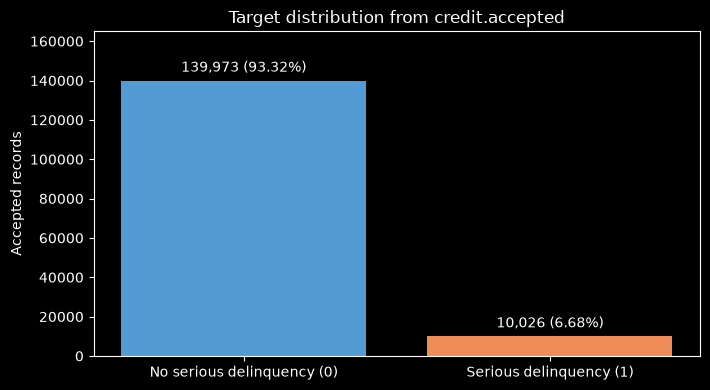

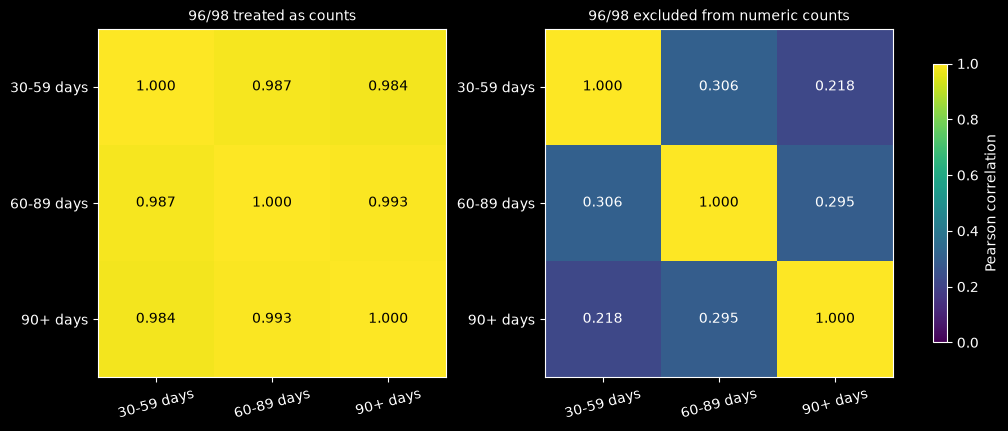

Section 1 evidence: stages\stage_03\evidence\section_01_dataset_understanding.json


In [7]:
import matplotlib.pyplot as plt

with plt.style.context("dark_background"):
    figure, axis = plt.subplots(figsize=(7.2, 4))
    bars = axis.bar(["No serious delinquency (0)", "Serious delinquency (1)"],
                    section1_class_table["records"].astype(int), color=["#529bd4", "#ef8b56"])
    axis.bar_label(bars, labels=[f"{int(n):,} ({p:.2f}%)" for n, p in
        zip(section1_class_table["records"], section1_class_table["percent"])], padding=4)
    axis.set_ylim(0, section1_sample_count * 1.1)
    axis.set_ylabel("Accepted records")
    axis.set_title("Target distribution from credit.accepted")
    figure.tight_layout()
    figure.savefig(section1_evidence_dir / "section_01_target_distribution.png", dpi=160)
    plt.show()

    figure, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
    for axis, matrix, title in zip(axes, [section1_corr_original, section1_corr_semantic],
                                  ["96/98 treated as counts", "96/98 excluded from numeric counts"]):
        image = axis.imshow(matrix.to_numpy(), vmin=0, vmax=1, cmap="viridis")
        axis.set_xticks(range(3), ["30-59 days", "60-89 days", "90+ days"], rotation=15)
        axis.set_yticks(range(3), ["30-59 days", "60-89 days", "90+ days"])
        axis.set_title(title, fontsize=10)
        for r in range(3):
            for c in range(3):
                axis.text(c, r, f"{matrix.iloc[r,c]:.3f}", ha="center", va="center",
                          color="black" if matrix.iloc[r,c] > .6 else "white")
    figure.colorbar(image, ax=axes, shrink=.8, label="Pearson correlation")
    figure.savefig(section1_evidence_dir / "section_01_sentinel_correlations.png", dpi=160)
    plt.show()

def section1_records(table):
    return json.loads(table.to_json(orient="records", force_ascii=False, double_precision=15))

section1_result = {
    "section": "Challenge 3, Section 1: dataset and target understanding",
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": {"database": section1_database, "table": "credit.accepted",
        "query": "SELECT * FROM credit.accepted ORDER BY row_id",
        "dictionary": "data/stage_03/raw/Data Dictionary.xls",
        "dictionary_sha256": section1_dictionary_hash},
    "samples": section1_sample_count, "stored_columns": len(df_section1.columns),
    "input_features": section1_features, "target": section1_target,
    "duplicate_non_id_rows": int(df_section1.drop(columns="row_id").duplicated().sum()),
    "overview": section1_records(section1_overview),
    "dictionary": section1_records(section1_dictionary_table),
    "target_distribution": section1_records(section1_class_table),
    "numeric_profile": section1_records(section1_numeric_profile),
    "sentinel_fields": section1_records(section1_sentinel_table),
    "sentinel_patterns": section1_records(section1_sentinel_patterns),
    "sentinel_records": int(section1_sentinel_rows.sum()),
    "sentinel_cells": int(section1_sentinel_cells.sum().sum()),
    "sentinel_zero_open_lines": int(df_section1.loc[section1_sentinel_rows, "NumberOfOpenCreditLinesAndLoans"].eq(0).sum()),
    "correlation_comparison": section1_records(section1_correlation_comparison),
    "domain_rules": section1_records(section1_domain_rules),
    "unusual_values": section1_records(section1_unusual_values),
    "income_debt_groups": section1_records(section1_income_debt_table),
    "semantic_copy_missing": {str(k): int(v) for k, v in X_section1.isna().sum().items()},
    "sentinel_policy": "Mask 96/98 only in the semantic analysis copy; retain original codes and flags separately. Exact code meanings are undocumented.",
    "data_modifications": "No database/file changes; semantic DataFrame copy only. No imputation, clipping, scaling, splitting or training.",
    "evaluation_scope": "Whole-table structural/descriptive analysis; no target-conditioned feature selection or preprocessing fit.",
}
section1_result_path = section1_evidence_dir / "section_01_dataset_understanding.json"
section1_result_path.write_text(json.dumps(section1_result, ensure_ascii=False, indent=2) + chr(10), encoding="utf-8")
print("Section 1 evidence:", section1_result_path.relative_to(PROJECT_ROOT))

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۵. بخش دو چالش: الگوی گمشدگی و انتخاب سیاست

<p dir="rtl" style="direction:rtl;text-align:right;">در این بخش، ابتدا مجموعه ارزیابی نهایی کنار گذاشته می‌شود. تمام بررسی‌های وابسته به برچسب، یادگیری مقدار جایگزین و مقایسه سیاست‌ها فقط روی داده توسعه انجام می‌شوند. داده از همان جدول دیتابیس و از طریق <bdi dir="ltr">SQLAlchemy</bdi> می‌آید.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">مقایسه شامل سه سیاست است: میانه، میانه با نشانگر گمشدگی و مقدار پرتکرار با نشانگر گمشدگی. منطق قابل استفاده مجدد در <code dir="ltr">src/data_factory/credit_missingness.py</code> قرار دارد. این مطالعه برای انتخاب سیاست است؛ مدل نهایی و آستانه بهینه چالش را تعیین نمی‌کند.</p>

</div>

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۵.۱. کنار گذاشتن ارزیابی نهایی و تثبیت تقسیم‌ها

<p dir="rtl" style="direction:rtl;text-align:right;">تقریباً ۲۰ درصد رکوردها با تقسیم طبقه‌بندی‌شده و گروهی کنار گذاشته می‌شوند. گروه، رکوردهای دارای ورودی معنایی کاملاً یکسان است؛ شناسه و هدف جزو تعریف گروه نیستند. این کار از قرار گرفتن نسخه‌های یکسان ورودی در دو سوی ارزیابی جلوگیری می‌کند، بدون اینکه ادعا کنیم هویت اشخاص را می‌شناسیم.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">عضویت مجموعه نهایی و پنج تکه توسعه در فایل <code dir="ltr">section_02_partition.json</code> ذخیره و در اجرای مجدد استفاده می‌شود. مجموعه نهایی در این بخش امتیازدهی نمی‌شود. بخش یک قبلاً کل جدول را به‌صورت ساختاری توصیف کرده است؛ ادعا نمی‌کنیم پیش از این هیچ توصیفی از رکوردهای نهایی ندیده‌ایم.</p>

</div>

In [2]:
import importlib
import json
from pathlib import Path
import pandas as pd
from data_factory.database.connection import create_database_engine
import data_factory.credit_missingness as missingness

missingness = importlib.reload(missingness)
if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
if "engine" not in globals():
    engine = create_database_engine()

section2_evidence_dir = PROJECT_ROOT / "stages/stage_03/evidence"
section2_frame, section2_database = missingness.read_credit_data(engine)
section2_partition = missingness.reserve_partition(
    section2_frame, section2_evidence_dir / "section_02_partition.json",
    seed=42, n_splits=5,
)
X_development, y_development, section2_groups, section2_folds = missingness.development_data(
    section2_frame, section2_partition
)
del section2_frame

section2_split_table = pd.DataFrame([
    {"partition": "development", "records": len(X_development),
     "usage": "missingness diagnostics and five-fold policy comparison"},
    {"partition": "final holdout", "records": len(section2_partition["holdout_row_ids"]),
     "usage": "reserved; no predictions or scores in Section 2"},
])
display(section2_split_table)
print("Development positive percent:", round(100 * y_development.mean(), 4))
print("Identifier is a feature:", "row_id" in X_development.columns)
print("Target is a feature:", missingness.TARGET in X_development.columns)
print("Partition manifest:", "stages/stage_03/evidence/section_02_partition.json")

,partition,records,usage
0,development,120000,missingness diagnostics and five-fold policy c...
1,final holdout,29999,reserved; no predictions or scores in Section 2


Development positive percent: 6.6842
Identifier is a feature: False
Target is a feature: False
Partition manifest: stages/stage_03/evidence/section_02_partition.json


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۵.۲. آیا نبود مقدار خودش اطلاعات دارد؟

<p dir="rtl" style="direction:rtl;text-align:right;">گمشده‌های اصلی درآمد و تعداد افراد تحت تکفل، از گمشده‌های حاصل از تبدیل کدهای ۹۶/۹۸ جدا گزارش می‌شوند. سه ستون دیرکرد در این داده یک الگوی مشترک دارند؛ در بررسی رابطه با هدف، این الگو یک بار بررسی می‌شود تا یک شاهد سه بار شمرده نشود.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">نرخ پیامد در گروه دارای مقدار و گروه فاقد مقدار، همراه با فاصله اطمینان ویلسون و اختلاف درصدی محاسبه می‌شود. رابطه با سن، تعداد خطوط اعتبار و لگاریتم نسبت بدهی نیز با اندازه اثر و مقایسه توزیع‌ها بررسی می‌شود. مقادیر احتمال در هر خانواده مقایسه با روش هولم تعدیل می‌شوند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">ارتباط با داده مشاهده‌شده می‌تواند فرض گمشدگی کاملاً تصادفی یا <bdi dir="ltr">MCAR</bdi> را زیر سؤال ببرد. این بررسی علت گمشدگی یا تفاوت قطعی <bdi dir="ltr">MAR</bdi> و <bdi dir="ltr">MNAR</bdi> را مشخص نمی‌کند. رابطه با پیامد، مجوز استفاده از پیامد در جایگزینی مقدار گمشده نیست.</p>

</div>

In [3]:
section2_diagnostics = missingness.missingness_diagnostics(X_development, y_development)
display(section2_diagnostics["missing_summary"])
display(section2_diagnostics["target_associations"][[
    "pattern", "missing_records", "observed_records",
    "positive_rate_missing_percent", "positive_rate_observed_percent",
    "risk_difference_pp", "odds_ratio", "p_holm",
]])
display(section2_diagnostics["feature_associations"])
display(section2_diagnostics["joint_patterns"])

,column,missing,percent
0,NumberOfTime30-59DaysPastDueNotWorse,209,0.174167
1,MonthlyIncome,23817,19.847500
2,NumberOfTimes90DaysLate,209,0.174167
3,NumberOfTime60-89DaysPastDueNotWorse,209,0.174167
4,NumberOfDependents,3141,2.617500


,pattern,missing_records,observed_records,positive_rate_missing_percent,positive_rate_observed_percent,risk_difference_pp,odds_ratio,p_holm
0,income_missing,23817,96183,5.517068,6.973166,-1.456098,0.778992,3.968579e-16
1,dependents_missing,3141,116859,4.075135,6.754294,-2.679158,0.586489,2.654843e-10
2,delinquency_sentinel,209,119791,52.153110,6.604837,45.548273,15.413057,5.544046e-70


,pattern,observed_feature,median_when_missing,median_when_observed,standardized_mean_difference,rank_biserial,p_value,p_holm
0,income_missing,age,57.000000,51.000000,0.343458,0.197431,0.000000e+00,0.000000e+00
1,income_missing,open_credit_lines,6.000000,8.000000,-0.314138,-0.194333,0.000000e+00,0.000000e+00
2,income_missing,log1p_debt_ratio,7.050123,0.260082,3.213311,0.875274,0.000000e+00,0.000000e+00
3,dependents_missing,age,61.000000,52.000000,0.452431,0.267818,3.268648e-145,1.307459e-144
4,dependents_missing,open_credit_lines,5.000000,8.000000,-0.631915,-0.365948,1.949217e-270,9.746086e-270
5,dependents_missing,log1p_debt_ratio,5.880533,0.306592,1.379291,0.588168,0.000000e+00,0.000000e+00
6,delinquency_sentinel,age,28.000000,52.000000,-1.345185,-0.665759,2.594589e-62,2.594589e-62
7,delinquency_sentinel,open_credit_lines,0.000000,8.000000,-2.336405,-0.989114,8.477179e-136,2.543154e-135
8,delinquency_sentinel,log1p_debt_ratio,0.000000,0.313499,-0.560347,-0.783854,1.253261e-85,2.506522e-85


,income_missing,dependents_missing,delinquency_sentinel,records,positives,positive_percent
0,0,0,0,96069,6646,6.917944
1,0,0,1,114,61,53.508772
2,1,0,0,20600,1147,5.567961
3,1,0,1,76,39,51.315789
4,1,1,0,3122,119,3.811659
5,1,1,1,19,9,47.368421


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۵.۳. مقایسه سه سیاست روی داده و مدل یکسان

<p dir="rtl" style="direction:rtl;text-align:right;">سیاست اول، جایگزینی مقدار گمشده با میانه ستون در داده آموزش است. سیاست دوم همین مقدار را به همراه نشانگر گمشدگی وارد مدل می‌کند. سیاست سوم از مقدار پرتکرار داده آموزش به همراه نشانگر استفاده می‌کند. ردیف‌های ناقص از ارزیابی حذف نمی‌شوند؛ هر سه روش برای تمام ردیف‌های ارزیابی پیش‌بینی دارند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">در هر پنج تکه، ابتدا جایگزینی مقدار گمشده، سپس تبدیل ثابت <code dir="ltr">log1p</code> و مقیاس‌بندی انجام می‌شود و یک طبقه‌بند لجستیک ثابت آموزش می‌بیند. مقدار جایگزین و پارامترهای مقیاس‌بندی درون همان Pipeline و فقط با تکه آموزش یاد گرفته می‌شوند. تبدیل لگاریتمی، نسخه مشترک آزمایش برای کنترل دنباله‌هاست و حد برش از کل داده نمی‌سازد.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">برای مقایسه، آستانه ثابت <code dir="ltr">1/13</code> از نسبت هزینه خطاهای ۱۲ به ۱ انتخاب شده است. این آستانه تحت احتمال‌های کالیبره، مرز نظری هزینه است؛ بهینه تجربی یا نهایی ادعا نمی‌شود و روی تکه ارزیابی تنظیم نشده است. معیار اصلی هزینه به ازای هزار نفر است؛ AUC، میانگین دقت و خطای بریر شواهد مکمل‌اند.</p>

</div>

In [4]:
section2_comparison = missingness.compare_policies(
    X_development, y_development, section2_groups, section2_folds
)
display(section2_comparison["summary"][[
    "policy", "records", "cost_per_1000", "fold_cost_std", "roc_auc",
    "average_precision", "brier", "recall", "output_features", "scored_coverage_percent",
]])
display(section2_comparison["fold_results"])
print("Reference decision threshold:", missingness.DECISION_THRESHOLD)

median, fold 1: cost/1000=410.600, AUC=0.8394


median, fold 2: cost/1000=429.464, AUC=0.8201


median, fold 3: cost/1000=434.851, AUC=0.8230


median, fold 4: cost/1000=418.684, AUC=0.8252


median, fold 5: cost/1000=405.608, AUC=0.8430


median_indicator, fold 1: cost/1000=407.434, AUC=0.8434


... (8 outputs left out)

most_frequent_indicator, fold 5: cost/1000=403.442, AUC=0.8463


,policy,records,cost_per_1000,fold_cost_std,roc_auc,average_precision,brier,recall,output_features,scored_coverage_percent
0,median_indicator,120000,416.183333,11.092819,0.833756,0.359672,0.051819,0.628351,15,100.0
1,most_frequent_indicator,120000,416.183333,11.092819,0.833756,0.359672,0.051819,0.628351,15,100.0
2,median,120000,419.841667,12.320934,0.830027,0.354005,0.052089,0.629223,10,100.0


,records,false_negative,false_positive,cost,cost_per_1000,roc_auc,average_precision,brier,recall,policy,fold,training_records,output_features
0,23999,573,2978,9854,410.600442,0.839432,0.374736,0.050976,0.642545,median,1,96001,10
1,24002,616,2916,10308,429.464211,0.820087,0.332145,0.053284,0.616199,median,2,95998,10
2,23999,629,2888,10436,434.851452,0.823010,0.343703,0.052460,0.607855,median,3,96001,10
3,23999,586,3016,10048,418.684112,0.825198,0.364831,0.051543,0.634663,median,4,96001,10
4,24001,570,2895,9735,405.608100,0.843028,0.358217,0.052182,0.644860,median,5,95999,10
5,23999,577,2854,9778,407.433643,0.843356,0.376773,0.050965,0.640050,median_indicator,1,96001,15
6,24002,614,2810,10178,424.047996,0.824300,0.338983,0.052926,0.617445,median_indicator,2,95998,15
7,23999,629,2772,10320,430.017917,0.827167,0.351517,0.052074,0.607855,median_indicator,3,96001,15
8,23999,589,2915,9983,415.975666,0.828231,0.369001,0.051372,0.632793,median_indicator,4,96001,15
9,24001,572,2819,9683,403.441523,0.846284,0.365951,0.051756,0.643614,median_indicator,5,95999,15


Reference decision threshold: 0.07692307692307693


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۵.۴. تفاوت زوجی و اثر سیاست بر ردیف‌های ناقص

<p dir="rtl" style="direction:rtl;text-align:right;">مقایسه زوجی یعنی هر دو هزینه از همان تکه ارزیابی به دست آمده‌اند. اختلاف منفی نسبت به سیاست میانه، کاهش هزینه را نشان می‌دهد. پراکندگی بین تکه‌ها گزارش می‌شود تا یک اختلاف کوچک به‌عنوان برتری قطعی معرفی نشود.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">هزینه روی رکوردهای ناقص و کامل نیز جدا گزارش می‌شود. امتیازهای اعتبارسنجی برای انتخاب سیاست استفاده شده‌اند؛ بنابراین برآورد مستقل عملکرد نهایی مدل نیستند. مجموعه نهایی برای ارزیابی پایان چالش دست‌نخورده می‌ماند.</p>

</div>

In [5]:
display(section2_comparison["paired_fold_costs"])
display(section2_comparison["subgroup_results"][[
    "policy", "subgroup", "records", "cost_per_1000", "roc_auc", "recall",
]])

policy,fold,median,median_indicator,most_frequent_indicator,median_indicator_minus_median,most_frequent_indicator_minus_median
0,1,410.600442,407.433643,407.433643,-3.166799,-3.166799
1,2,429.464211,424.047996,424.047996,-5.416215,-5.416215
2,3,434.851452,430.017917,430.017917,-4.833535,-4.833535
3,4,418.684112,415.975666,415.975666,-2.708446,-2.708446
4,5,405.608100,403.441523,403.441523,-2.166576,-2.166576


,policy,subgroup,records,cost_per_1000,roc_auc,recall
0,median,any_missing,23931,330.408257,0.873439,0.642909
1,median,complete,96069,442.119726,0.818471,0.626392
2,median_indicator,any_missing,23931,313.693536,0.880595,0.663273
3,median_indicator,complete,96069,441.713768,0.820777,0.621125
4,most_frequent_indicator,any_missing,23931,313.693536,0.880595,0.663273
5,most_frequent_indicator,complete,96069,441.713768,0.820777,0.621125


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۵.۵. مشاهده مرز یادگیری پارامترها

<p dir="rtl" style="direction:rtl;text-align:right;">جدول زیر پارامترهای جایگزینی واقعاً یادگرفته‌شده در هر تکه را نشان می‌دهد. تعداد نمونه برازش مقیاس‌بند باید همان تعداد تکه آموزش باشد. شناسه‌ها و گروه‌های ورودی یکسان در دو سوی هر تکه هم‌پوشانی ندارند.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">نشانگرها فقط به ماتریس ورودی مدل اضافه می‌شوند و CSV یا جدول دیتابیس ستون اضافه‌ای نمی‌گیرد. سه نشانگر مربوط به دیرکردها در این snapshot یکسان‌اند؛ این هم‌ارزی از الگوی کدگذاری می‌آید، نه از سه شاهد مستقل. مدل مرجع با منظم‌سازی آموزش داده می‌شود و این محدودیت در تفسیر مقایسه لحاظ می‌شود.</p>

</div>

In [6]:
section2_audit_table = pd.DataFrame([
    {"policy": item["policy"], "fold": item["fold"],
     "fit_records": item["fit_records"], "validation_records": item["validation_records"],
     "row_overlap": item["id_overlap"], "group_overlap": item["identical_input_group_overlap"],
     "income_fill": item["imputer_statistics"]["MonthlyIncome"],
     "dependents_fill": item["imputer_statistics"]["NumberOfDependents"],
     "late_30_59_fill": item["imputer_statistics"]["NumberOfTime30-59DaysPastDueNotWorse"],
     "scaler_fit_samples": item["scaler_fit_samples"]}
    for item in section2_comparison["fit_audit"]
])
display(section2_audit_table)

,policy,fold,fit_records,validation_records,row_overlap,group_overlap,income_fill,dependents_fill,late_30_59_fill,scaler_fit_samples
0,median,1,96001,23999,0,0,5400.0,0.0,0.0,96001
1,median,2,95998,24002,0,0,5400.0,0.0,0.0,95998
2,median,3,96001,23999,0,0,5400.0,0.0,0.0,96001
3,median,4,96001,23999,0,0,5400.0,0.0,0.0,96001
4,median,5,95999,24001,0,0,5400.0,0.0,0.0,95999
5,median_indicator,1,96001,23999,0,0,5400.0,0.0,0.0,96001
6,median_indicator,2,95998,24002,0,0,5400.0,0.0,0.0,95998
7,median_indicator,3,96001,23999,0,0,5400.0,0.0,0.0,96001
8,median_indicator,4,96001,23999,0,0,5400.0,0.0,0.0,96001
9,median_indicator,5,95999,24001,0,0,5400.0,0.0,0.0,95999


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۵.۶. سیاست منتخب و خروجی قابل استفاده

<p dir="rtl" style="direction:rtl;text-align:right;">سیاست با کمترین هزینه تجمیع پیش‌بینی‌های خارج از تکه آموزش انتخاب می‌شود؛ در برابری هزینه، روش با ورودی کمتر اولویت دارد؛ اگر تعداد ورودی نیز برابر باشد، ترتیب ثابت سیاست‌ها رعایت می‌شود و میانه پیش از مقدار پرتکرار قرار می‌گیرد. انتخاب، مشروط به مدل مرجع این بخش است و با تغییر خانواده مدل یا تنظیم آستانه ممکن است بازنگری شود.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">یک پیش‌پردازنده با سیاست منتخب فقط روی داده توسعه برازش می‌شود تا پارامترها و خروجی آن قابل مشاهده باشد. در اعتبارسنجی بخش‌های بعد، باید پیش‌پردازنده تازه داخل هر تکه آموزش ساخته شود؛ استفاده از این شیء از پیش برازش‌شده در CV مجاز نیست. مجموعه نهایی برای برازش یا انتخاب استفاده نمی‌شود.</p>

</div>

In [7]:
section2_result, section2_selected_preprocessor = missingness.save_study(
    section2_evidence_dir, section2_partition, section2_database,
    X_development, y_development, section2_diagnostics, section2_comparison,
)
section2_selected_policy = section2_result["selected_policy"]
print("Selected missingness policy:", section2_selected_policy["selected_policy"])
print("Development fit records:", section2_selected_policy["development_fit_records"])
print("Final holdout evaluations:", section2_selected_policy["holdout_evaluations"])
section2_preview = pd.DataFrame(
    section2_selected_preprocessor.transform(X_development.head()),
    columns=section2_selected_preprocessor.get_feature_names_out(),
    index=X_development.head().index,
)
display(section2_preview)
print("Evidence: stages/stage_03/evidence/section_02_missingness.json")
print("Policy: stages/stage_03/evidence/section_02_selected_policy.json")

Selected missingness policy: median_indicator
Development fit records: 120000
Final holdout evaluations: 0


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,missingindicator_NumberOfTime30-59DaysPastDueNotWorse,missingindicator_MonthlyIncome,missingindicator_NumberOfTimes90DaysLate,missingindicator_NumberOfTime60-89DaysPastDueNotWorse,missingindicator_NumberOfDependents
row_id,,,,,,,,,,,,,,,
1,0.822186,-0.362695,2.787140,-0.356740,0.560574,0.920265,-0.222645,2.746172,-0.216471,1.332004,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947
2,1.093140,-0.755951,-0.405252,-0.537409,-0.487378,-0.802691,-0.222645,-1.149303,-0.216471,0.564202,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947
3,0.655795,-0.926864,1.608923,-0.550096,-0.356290,-1.657502,2.904177,-1.149303,-0.216471,-0.748363,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947
4,-0.124118,-1.711448,-0.405252,-0.567716,-0.288318,-0.497596,-0.222645,-1.149303,-0.216471,-0.748363,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947
5,1.024986,-0.077733,1.608923,-0.571827,2.182479,-0.016191,-0.222645,0.238293,-0.216471,-0.748363,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947


Evidence: stages/stage_03/evidence/section_02_missingness.json
Policy: stages/stage_03/evidence/section_02_selected_policy.json


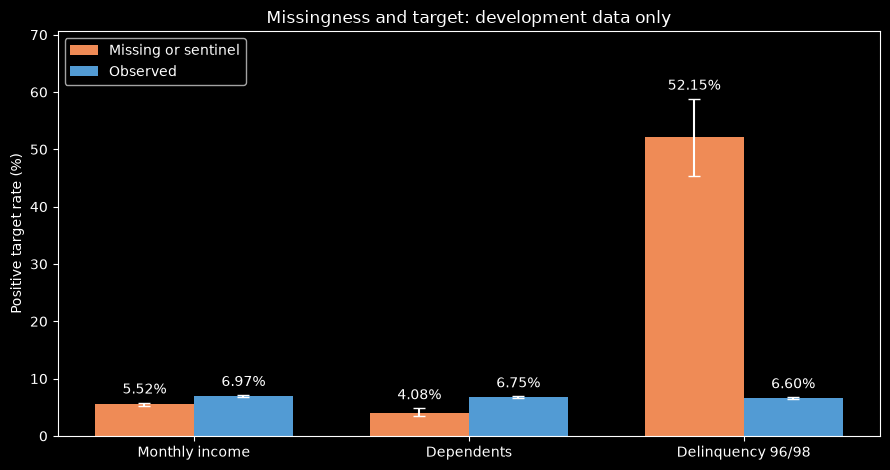

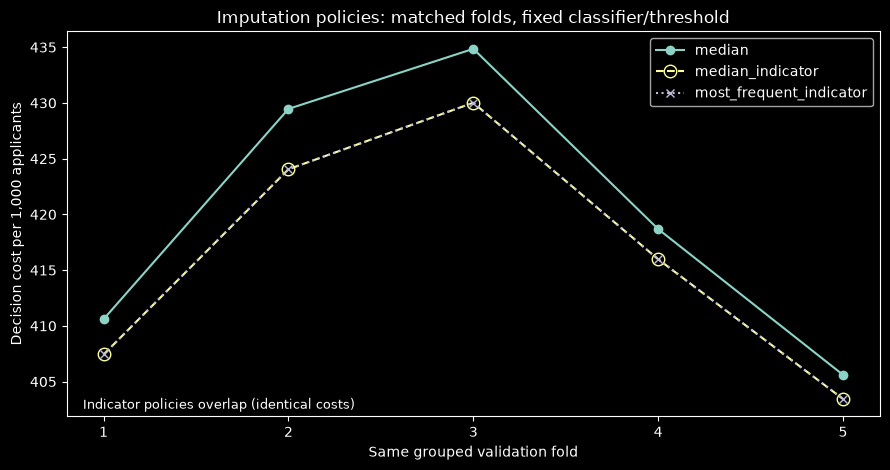

In [2]:
import numpy as np
import matplotlib.pyplot as plt

with plt.style.context("dark_background"):
    associations = section2_diagnostics["target_associations"]
    x = np.arange(len(associations))
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for offset, label, value, low, high, color in [
        (-.18, "Missing or sentinel", "positive_rate_missing_percent", "missing_rate_wilson_low", "missing_rate_wilson_high", "#ef8b56"),
        (.18, "Observed", "positive_rate_observed_percent", "observed_rate_wilson_low", "observed_rate_wilson_high", "#529bd4"),
    ]:
        rates = associations[value].to_numpy()
        errors = np.vstack([rates - associations[low].to_numpy(), associations[high].to_numpy() - rates])
        bars = ax.bar(x + offset, rates, width=.36, label=label, color=color)
        ax.errorbar(x + offset, rates, yerr=errors, fmt="none", ecolor="white", capsize=4)
        for position, rate, upper in zip(x + offset, rates, associations[high].to_numpy()):
            ax.text(position, upper + 1, f"{rate:.2f}%", ha="center", va="bottom")
    ax.set_xticks(x, ["Monthly income", "Dependents", "Delinquency 96/98"])
    ax.set_ylabel("Positive target rate (%)")
    ax.set_title("Missingness and target: development data only")
    ax.legend()
    ax.margins(y=.2)
    fig.tight_layout()
    fig.savefig(section2_evidence_dir / "section_02_missingness_rates.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.8))
    paired = section2_comparison["paired_fold_costs"]
    styles = {
        "median": {"color": "#8bd3c7", "marker": "o", "linestyle": "-"},
        "median_indicator": {"color": "#ffff99", "marker": "o", "linestyle": "--", "markerfacecolor": "none", "markersize": 9},
        "most_frequent_indicator": {"color": "#bebada", "marker": "x", "linestyle": ":", "markersize": 6},
    }
    for policy in missingness.POLICIES:
        ax.plot(paired["fold"], paired[policy], label=policy, **styles[policy])
    if np.array_equal(paired["median_indicator"], paired["most_frequent_indicator"]):
        ax.text(.02, .02, "Indicator policies overlap (identical costs)", transform=ax.transAxes, fontsize=9)
    ax.set_xticks(paired["fold"])
    ax.set_xlabel("Same grouped validation fold")
    ax.set_ylabel("Decision cost per 1,000 applicants")
    ax.set_title("Imputation policies: matched folds, fixed classifier/threshold")
    ax.legend()
    fig.tight_layout()
    fig.savefig(section2_evidence_dir / "section_02_policy_costs.png", dpi=160)
    plt.show()

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۵.۷. جمع‌بندی اجرای بخش دو

<p dir="rtl" style="direction:rtl;text-align:right;">در این اجرا، ۱۲۰٬۰۰۰ رکورد برای توسعه و ۲۹٬۹۹۹ رکورد برای ارزیابی نهایی کنار گذاشته شدند. امتیازی برای مجموعه نهایی محاسبه نشد. رابطه گمشدگی با سن، خطوط اعتبار، نسبت بدهی و پیامد نشان داد فرض بی‌اطلاع بودن نبود مقدار، توجیه کافی ندارد؛ اما سازوکار قطعی گمشدگی یا تمایز MAR و MNAR از این داده مشخص نمی‌شود.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">دو روش نشانگردار هزینه یکسان ۴۱۶٫۱۸۳ واحد در هزار داشتند؛ مرجع میانه بدون نشانگر ۴۱۹٫۸۴۲ بود. بهبود نسبت به مرجع حدود ۰٫۸۷۱ درصد و در هر پنج تکه هم‌جهت بود. با وجود برابری هزینه دو روش نشانگردار، سیاست میانه همراه نشانگر مطابق قاعده ثابت رفع برابری انتخاب شد؛ برتری هزینه‌ای میانه بر مقدار پرتکرار ادعا نمی‌شود.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">در سیاست منتخب، FP از ۱۴٬۶۹۳ به ۱۴٬۱۷۰ کاهش یافت، اما FN از ۲٬۹۷۴ به ۲٬۹۸۱ رسید. با هزینه ۱۲ برای هر FN و ۱ برای هر FP، هزینه کل ۴۳۹ واحد کمتر شد. پس انتخاب بر اساس هزینه است و به معنی بهتر شدن هم‌زمان همه معیارها نیست.</p>

<p dir="rtl" style="direction:rtl;text-align:right;">اطلاعات نبود مقدار با نشانگر حفظ می‌شود و هیچ ردیفی از ارزیابی حذف نشده است. در مقابل، پنج ورودی مدل اضافه می‌شود و سه نشانگر دیرکرد در این snapshot تکراری‌اند. پرکردن نقطه‌ای مقدار واقعی ناشناخته یا علت گمشدگی را بازیابی نمی‌کند. ارزیابی مدل نهایی و انتخاب آستانه تجربی به بخش‌های بعد تعلق دارند.</p>

</div>

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۶. بخش سه: آماده‌سازی با مرز نشت‌ناپذیر

<p dir="rtl" style="direction:rtl;text-align:right;">Pipeline از داده خامِ پذیرفته‌شده شروع می‌کند: کنترل schema، حذف شناسه/هدف، تبدیل کدهای ۹۶/۹۸ و جایگزینی مطابق سیاست منتخب. همان عضویت‌های بخش دو استفاده می‌شوند و مجموعه نهایی امتیازدهی نمی‌شود.</p>

</div>

In [2]:
import importlib
from pathlib import Path
import pandas as pd
from data_factory.database.connection import create_database_engine
import data_factory.credit_preprocessing as preprocessing

preprocessing = importlib.reload(preprocessing)
if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
if "engine" not in globals():
    engine = create_database_engine()

section3_dir = PROJECT_ROOT / "stages/stage_03/evidence"
(section3_raw, section3_y, section3_groups, section3_folds,
 section3_partition, section3_choice, section3_database) = preprocessing.load_development(engine, section3_dir)
section3_policy = section3_choice["selected_policy"]
print("Development records:", len(section3_raw))
print("Reserved final records:", len(section3_partition["holdout_row_ids"]))
print("Policy:", section3_policy)
print("Model input columns:", list(preprocessing.FEATURES))

Development records: 120000
Reserved final records: 29999
Policy: median_indicator
Model input columns: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۶.۱. Encoding و Scaling

<p dir="rtl" style="direction:rtl;text-align:right;">ورودی اسمی نداریم؛ نشانگرهای گمشدگی با ۰/۱ و schema ثابت کدگذاری می‌شوند. لجستیک از <code dir="ltr">log1p + StandardScaler</code> استفاده می‌کند، چون منظم‌سازی و بهینه‌سازی آن به مقیاس حساس‌اند. برای مدل درختی مقیاس‌بندی لازم نیست، چون تقسیم‌ها بر ترتیب و آستانه ویژگی‌ها متکی‌اند.</p>

</div>

In [3]:
(section3_fold_audit, section3_fold_states,
 section3_first_preprocessors, section3_legacy_error) = preprocessing.audit_fold_boundaries(
    section3_raw, section3_groups, section3_folds, section3_policy
)
display(section3_fold_audit)
display(pd.DataFrame([
    {"family": item["family"], "fold": item["fold"],
     "fit_records": item["schema_fit_rows"],
     "income_fill": item["imputation_statistics"]["MonthlyIncome"],
     "scaler_fit_records": item["scaler"]["fit_rows"] if item["scaler"] else None}
    for item in section3_fold_states
]))
print("Maximum difference from the selected Section 2 transform:", section3_legacy_error)

,family,fold,train_records,validation_records,row_overlap,group_overlap,output_columns,finite_output,training_fill_max_error,scaler_training_mean_max_error,scaler_training_variance_max_error,fit_state_unchanged_after_transform
0,logistic,1,96001,23999,0,0,15,True,0.0,0.0,0.0,True
1,logistic,2,95998,24002,0,0,15,True,0.0,0.0,0.0,True
2,logistic,3,96001,23999,0,0,15,True,0.0,0.0,0.0,True
3,logistic,4,96001,23999,0,0,15,True,0.0,0.0,0.0,True
4,logistic,5,95999,24001,0,0,15,True,0.0,0.0,0.0,True
5,hist_gradient_boosting,1,96001,23999,0,0,15,True,0.0,0.0,0.0,True
6,hist_gradient_boosting,2,95998,24002,0,0,15,True,0.0,0.0,0.0,True
7,hist_gradient_boosting,3,96001,23999,0,0,15,True,0.0,0.0,0.0,True
8,hist_gradient_boosting,4,96001,23999,0,0,15,True,0.0,0.0,0.0,True
9,hist_gradient_boosting,5,95999,24001,0,0,15,True,0.0,0.0,0.0,True


,family,fold,fit_records,income_fill,scaler_fit_records
0,logistic,1,96001,5400.0,96001.0
1,logistic,2,95998,5400.0,95998.0
2,logistic,3,96001,5400.0,96001.0
3,logistic,4,96001,5400.0,96001.0
4,logistic,5,95999,5400.0,95999.0
5,hist_gradient_boosting,1,96001,5400.0,NaN
6,hist_gradient_boosting,2,95998,5400.0,NaN
7,hist_gradient_boosting,3,96001,5400.0,NaN
8,hist_gradient_boosting,4,96001,5400.0,NaN
9,hist_gradient_boosting,5,95999,5400.0,NaN


Maximum difference from the selected Section 2 transform: 0.0


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۶.۲. داده جدید با همان schema

<p dir="rtl" style="direction:rtl;text-align:right;">Pipeline بدون fit دوباره، جابه‌جایی ستون‌ها، نبود شناسه/برچسب و گمشده‌های مجاز جدید را می‌پذیرد. ستون یا مقدار ناسازگار با قرارداد، خطای روشن می‌دهد. تغییر مقادیر ارزیابی نباید پارامترهای آموخته‌شده را تغییر دهد.</p>

</div>

In [4]:
_, _, section3_valid_positions = section3_folds[0]
section3_batch_audit, section3_schema_rejections = preprocessing.audit_new_batches(
    section3_first_preprocessors, section3_raw.iloc[section3_valid_positions]
)
display(section3_batch_audit)
display(section3_schema_rejections)

# Execute each complete model pipeline on one development fold; no scores.
section3_model_execution = preprocessing.audit_model_execution(
    section3_raw, section3_y, section3_folds, section3_policy
)
display(section3_model_execution)

,family,records,reordered_columns_max_error,changed_id_target_max_error,new_missing_and_extreme_values_finite,same_output_schema,learned_parameters_unchanged
0,logistic,32,0.0,0.0,True,True,True
1,hist_gradient_boosting,32,0.0,0.0,True,True,True


,case,rejected,reason
0,missing_column,True,"Schema mismatch: missing=['age'], unexpected=[]"
1,unexpected_column,True,"Schema mismatch: missing=[], unexpected=['unex..."
2,invalid_numeric_category,True,Invalid numeric input in age
3,nonpositive_age,True,Age must be positive.
4,unexpected_missing_age,True,Missing values violate the accepted schema: ['...
5,negative_income,True,"Numeric inputs must be finite/nonnegative, apa..."
6,fractional_dependents,True,A whole-number count/year is required in Numbe...
7,infinite_debt_ratio,True,"Numeric inputs must be finite/nonnegative, apa..."
8,duplicate_header,True,Duplicate input column names are not allowed.


,family,fit_records,prediction_probe_records,preprocessing_inside_model_pipeline,valid_probabilities,scaled,performance_metrics_computed
0,logistic,96001,32,True,True,True,False
1,hist_gradient_boosting,96001,32,True,True,False,False


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۶.۳. ذخیره و استفاده مجدد

<p dir="rtl" style="direction:rtl;text-align:right;">دو پیش‌پردازنده فقط روی توسعه برازش و ذخیره می‌شوند؛ فایل ورودی تازه پس از عبور از Data Factory و دیتابیس، بدون تغییر کد با همین schema تبدیل می‌شود. فایل ذخیره‌شده برای inference است؛ برای CV بعدی، Pipeline تازه بسازید و فقط روی آموزش همان تکه fit کنید.</p>

</div>

In [5]:
section3_artifact = section3_dir / "section_03_preprocessors.joblib"
section3_bundle, section3_artifact_metadata, section3_reload_audit = preprocessing.save_preprocessors(
    section3_raw, section3_policy, section3_partition, section3_artifact
)
section3_result = preprocessing.save_evidence(
    section3_dir / "section_03_preprocessing.json",
    database=section3_database, partition=section3_partition, policy=section3_policy,
    fold_audit=section3_fold_audit, fold_states=section3_fold_states,
    batch_audit=section3_batch_audit, schema_rejections=section3_schema_rejections,
    model_execution=section3_model_execution, artifact_metadata=section3_artifact_metadata,
    reload_audit=section3_reload_audit, legacy_max_error=section3_legacy_error,
)
display(section3_reload_audit)

# Transform only. The reloaded preprocessor is not fitted on this batch.
new_rows = section3_raw.iloc[section3_valid_positions].head().loc[:, list(preprocessing.FEATURES)]
section3_preview = preprocessing.transform_frame(section3_bundle["preprocessors"]["logistic"], new_rows)
display(section3_preview)
print("Saved:", section3_artifact.relative_to(PROJECT_ROOT))
print("Feature columns:", section3_preview.shape[1])
print("Final holdout evaluations:", section3_result["holdout_evaluations"])

# Future CV must fit a new complete pipeline inside each training fold:
logistic_pipeline = preprocessing.make_model_pipeline(family="logistic", policy=section3_policy)
tree_pipeline = preprocessing.make_model_pipeline(family="hist_gradient_boosting", policy=section3_policy)

,family,reload_max_error,output_columns,same_names_after_reload
0,logistic,0.0,15,True
1,hist_gradient_boosting,0.0,15,True


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,missingindicator_NumberOfTime30-59DaysPastDueNotWorse,missingindicator_MonthlyIncome,missingindicator_NumberOfTimes90DaysLate,missingindicator_NumberOfTime60-89DaysPastDueNotWorse,missingindicator_NumberOfDependents
row_id,,,,,,,,,,,,,,,
4,-0.124118,-1.711448,-0.405252,-0.567716,-0.288318,-0.497596,-0.222645,-1.149303,-0.216471,-0.748363,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947
9,-0.386639,-2.059297,-0.405252,0.884948,0.122916,-1.657502,-0.222645,-1.149303,-0.216471,-0.748363,-0.04177,2.009582,-0.04177,-0.04177,6.099540
15,-0.627083,1.397908,-0.405252,1.768209,-7.055354,-0.239641,-0.222645,0.238293,-0.216471,-0.748363,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947
18,-0.272611,0.185286,-0.405252,-0.515513,0.530744,-0.016191,-0.222645,-1.149303,-0.216471,-0.748363,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947
29,0.306424,-2.446604,-0.405252,-0.576750,-0.263391,-2.336004,-0.222645,-1.149303,-0.216471,-0.748363,-0.04177,-0.497616,-0.04177,-0.04177,-0.163947


Saved: stages\stage_03\evidence\section_03_preprocessors.joblib
Feature columns: 15
Final holdout evaluations: 0


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۷. بخش چهار: مهندسی ویژگی و ممیزی نشت

<p dir="rtl" style="direction:rtl;text-align:right;">چهار ویژگی با منطق اعتباری ساخته می‌شوند؛ نشانگرهای گمشدگی جزو این چهار ویژگی نیستند. محاسبه بعد از جایگزینیِ فقط‌آموزشی و پیش از مقیاس‌بندی، داخل Pipeline انجام می‌شود. همان تقسیم‌های بخش دو حفظ می‌شوند.</p>

</div>

In [2]:
import importlib
from pathlib import Path
import pandas as pd
from data_factory.database.connection import create_database_engine
import data_factory.credit_preprocessing as preprocessing
import data_factory.credit_feature_engineering as engineering

engineering = importlib.reload(engineering)
if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
if "engine" not in globals():
    engine = create_database_engine()

section4_dir = PROJECT_ROOT / "stages/stage_03/evidence"
(section4_raw, section4_y, section4_groups, section4_folds,
 section4_partition, section4_choice, section4_database) = preprocessing.load_development(engine, section4_dir)
section4_policy = section4_choice["selected_policy"]
section4_contract = engineering.audit_feature_contract(section4_raw, section4_folds, section4_policy)

# Full text with wrapping; styles apply only to this feature table.
from IPython.display import HTML

with pd.option_context("display.max_colwidth", None):
    display(HTML(
        """<style>
        #section4_feature_definitions table {
            width: 100%; table-layout: fixed; border-collapse: collapse;
            background: #1e1e1e; color: #e0e0e0;
        }
        #section4_feature_definitions td,
        #section4_feature_definitions th {
            white-space: normal; overflow-wrap: anywhere; vertical-align: top;
            padding: 10px; border: 1px solid #444;
        }
        #section4_feature_definitions th {
            background: #292929; color: #e0e0e0; text-align: left;
        }
        #section4_feature_definitions td {
            background: #1e1e1e; color: #e0e0e0;
        }
        #section4_feature_definitions td:nth-child(-n+2) {
            direction: ltr; text-align: left;
        }
        #section4_feature_definitions td:nth-child(n+3) {
            direction: rtl; text-align: right; unicode-bidi: plaintext;
        }
        #section4_feature_definitions th:nth-child(1) { width: 18%; }
        #section4_feature_definitions th:nth-child(2) { width: 24%; }
        #section4_feature_definitions th:nth-child(3),
        #section4_feature_definitions th:nth-child(4) { width: 29%; }
        </style><div id="section4_feature_definitions">"""
        + pd.DataFrame(engineering.FEATURE_DEFINITIONS)[
            ["name", "formula", "hypothesis", "availability"]
        ].to_html(index=False, escape=True, border=0)
        + "</div>"
    ))
display(pd.DataFrame([{
    "source_columns_only": section4_contract["approved_sources_only"],
    "target_id_change_error": section4_contract["target_and_id_max_error"],
    "formula_edge_error": section4_contract["formula_edge_cases_max_error"],
    "other_rows_change_error": section4_contract["other_inference_rows_max_error"],
    "fit_state_unchanged": section4_contract["state_unchanged_after_transform"],
}]))
print("Development records:", len(section4_raw))
print("Reserved final records:", len(section4_partition["holdout_row_ids"]))

name,formula,hypothesis,availability
TotalDelinquencyCount,late30 + late60 + late90,تجمیع شمارش‌های دیرکرد، نشانه ریسک را بهتر از هر ستون به‌تنهایی نشان می‌دهد.,سابقه اعتباری موجود هنگام درخواست وام؛ بدون استفاده از پیامد دو سال بعد.
SeverityWeightedDelinquency,late30 + 2*late60 + 3*late90,تکرار دیرکردهای شدیدتر، نشانه ریسک بیشتری است؛ وزن‌های ۱، ۲ و ۳ از پیش ثابت‌اند.,همان سابقه پیش از تصمیم؛ وزن‌ها از برچسب یا داده ارزیابی آموخته نمی‌شوند.
RealEstateToOpenCreditRatio,real_estate / open_credit if open_credit > 0 else 0,ترکیب وام‌های ملکی و سایر خطوط اعتباری با ریسک ارتباط دارد؛ مخرج صفر، خروجی صفر دارد.,ترکیب تعهدات موجود هنگام درخواست؛ بدون استفاده از نتیجه وام جدید.
UtilizationDebtInteraction,utilization * debt_ratio,هم‌زمانی استفاده زیاد از اعتبار و بار بدهی بالا، ریسک مضاعفی را نشان می‌دهد.,نسبت‌های ثبت‌شده در پرونده هنگام تصمیم؛ بدون اطلاعات بازپرداخت آینده.


,source_columns_only,target_id_change_error,formula_edge_error,other_rows_change_error,fit_state_unchanged
0,True,0.0,0.0,0.0,True


Development records: 120000
Reserved final records: 29999


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۷.۱. مقایسه اثر ویژگی‌ها

<p dir="rtl" style="direction:rtl;text-align:right;">۱۶ ترکیب ممکن روی پنج تقسیم ثابت، برای دو مدل مرجع فعلی مقایسه می‌شوند. معیار انتخاب، هزینه <code dir="ltr">12 × FN + FP</code> در آستانه ثابت <code dir="ltr">1/13</code> است؛ در برابری، ستون کمتر ترجیح دارد. سیاست گمشده‌ها ثابت می‌ماند تا اثر ویژگی‌ها قابل مقایسه باشد. این اعداد برای انتخاب روی توسعه‌اند و برآورد نهایی عملکرد نیستند.</p>

</div>

In [3]:
(section4_summary, section4_fold_results,
 section4_fit_audit, section4_first_preprocessors) = engineering.compare_feature_subsets(
    section4_raw, section4_y, section4_groups, section4_folds,
    policy=section4_policy, progress=print,
)
section4_selected, section4_decisions, section4_effects = engineering.select_features(section4_summary)

display(section4_decisions[[
    "family", "selected_features", "input_columns", "original_cost_per_1000",
    "selected_cost_per_1000", "relative_cost_reduction_percent", "selected_fold_cost_std",
]])
display(section4_effects[[
    "family", "feature", "single_addition_change_per_1000", "cost_without_per_1000",
    "cost_with_per_1000", "conditional_change_per_1000", "decision",
]])
display(section4_fit_audit.groupby("family", as_index=False).agg(
    fits=("fold", "size"), row_overlap=("row_overlap", "max"),
    group_overlap=("group_overlap", "max"), fill_error=("training_fill_max_error", "max"),
    scaler_mean_error=("scaler_training_mean_max_error", "max"),
    scaler_variance_error=("scaler_training_variance_max_error", "max"),
    state_unchanged=("parameters_unchanged_after_validation", "all"),
))

logistic: original


logistic: TotalDelinquencyCount


logistic: SeverityWeightedDelinquency


logistic: RealEstateToOpenCreditRatio


logistic: UtilizationDebtInteraction


logistic: TotalDelinquencyCount+SeverityWeightedDelinquency


... (25 outputs left out)

hist_gradient_boosting: TotalDelinquencyCount+SeverityWeightedDelinquency+RealEstateToOpenCreditRatio+UtilizationDebtInteraction


,family,selected_features,input_columns,original_cost_per_1000,selected_cost_per_1000,relative_cost_reduction_percent,selected_fold_cost_std
0,logistic,"[SeverityWeightedDelinquency, UtilizationDebtI...",17,416.183333,410.833333,1.285491,12.546848
1,hist_gradient_boosting,"[TotalDelinquencyCount, SeverityWeightedDelinq...",18,371.975000,369.300000,0.719134,10.823190


,family,feature,single_addition_change_per_1000,cost_without_per_1000,cost_with_per_1000,conditional_change_per_1000,decision
0,logistic,TotalDelinquencyCount,-4.258333,410.833333,411.258333,0.425000,drop
1,logistic,SeverityWeightedDelinquency,-4.475000,416.216667,410.833333,-5.383333,keep
2,logistic,RealEstateToOpenCreditRatio,0.183333,410.833333,410.966667,0.133333,drop
3,logistic,UtilizationDebtInteraction,0.033333,411.708333,410.833333,-0.875000,keep
4,hist_gradient_boosting,TotalDelinquencyCount,-0.941667,370.966667,369.300000,-1.666667,keep
5,hist_gradient_boosting,SeverityWeightedDelinquency,-1.866667,372.741667,369.300000,-3.441667,keep
6,hist_gradient_boosting,RealEstateToOpenCreditRatio,0.050000,370.933333,369.300000,-1.633333,keep
7,hist_gradient_boosting,UtilizationDebtInteraction,0.941667,369.300000,371.233333,1.933333,drop


,family,fits,row_overlap,group_overlap,fill_error,scaler_mean_error,scaler_variance_error,state_unchanged
0,hist_gradient_boosting,80,0,0,0.0,0.0,0.0,True
1,logistic,80,0,0,0.0,0.0,0.0,True


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۷.۲. تصمیم و استفاده بعدی

<p dir="rtl" style="direction:rtl;text-align:right;">در جدول اثر، تغییر منفی هزینه به نفع ویژگی است. اثر شرطی برای ویژگی نگه‌داشته‌شده، حذف آن از ترکیب منتخب را مقایسه می‌کند؛ برای ویژگی حذف‌شده، افزودن آن به ترکیب منتخب را. دسترسی پیش از وام بر فرض زمانی صورت‌مسئله استوار است؛ داده مهر زمانی ندارد. تغییر برچسب/شناسه اثری بر ویژگی‌ها ندارد، اما این کنترل جای تأیید زمان ثبت ورودی را نمی‌گیرد.</p>

</div>

In [4]:
section4_result = engineering.save_study(
    section4_dir, database=section4_database, partition=section4_partition,
    policy=section4_policy, contract_audit=section4_contract,
    summary=section4_summary, fold_results=section4_fold_results, fit_audit=section4_fit_audit,
    selected=section4_selected, decisions=section4_decisions, effects=section4_effects,
)

# Fresh, UNFITTED complete sklearn Pipelines for subsequent training.
section4_logistic_pipeline = engineering.make_feature_pipeline(
    family="logistic", features=section4_selected["logistic"], policy=section4_policy)
section4_tree_pipeline = engineering.make_feature_pipeline(
    family="hist_gradient_boosting", features=section4_selected["hist_gradient_boosting"], policy=section4_policy)

# Preview uses only a first-fold TRAIN-fitted preprocessor, with no refit.
_, _, section4_validation_positions = section4_folds[0]
section4_new_rows = section4_raw.iloc[section4_validation_positions].head()
section4_previews = {}
for family, names in section4_selected.items():
    fitted_preprocessor = section4_first_preprocessors[(family, engineering.subset_key(names))]
    section4_previews[family] = preprocessing.transform_frame(fitted_preprocessor, section4_new_rows)
    print(family, "new features:", list(names), "output columns:", section4_previews[family].shape[1])
    display(section4_previews[family])
print("Final holdout evaluations:", section4_result["holdout_evaluations"])
print("Evidence:", (section4_dir / "section_04_feature_engineering.json").relative_to(PROJECT_ROOT))

logistic new features: ['SeverityWeightedDelinquency', 'UtilizationDebtInteraction'] output columns: 17


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,missingindicator_NumberOfTime30-59DaysPastDueNotWorse,missingindicator_MonthlyIncome,missingindicator_NumberOfTimes90DaysLate,missingindicator_NumberOfTime60-89DaysPastDueNotWorse,missingindicator_NumberOfDependents,SeverityWeightedDelinquency,UtilizationDebtInteraction
row_id,,,,,,,,,,,,,,,,,
4,-0.122548,-1.710275,-0.404071,-0.567717,-0.290123,-0.497444,-0.22199,-1.151236,-0.21561,-0.747387,-0.041241,-0.498075,-0.041241,-0.041241,-0.163113,-0.439762,-0.453921
9,-0.384622,-2.057898,-0.404071,0.883620,0.122306,-1.657434,-0.22199,-1.151236,-0.21561,-0.747387,-0.041241,2.007728,-0.041241,-0.041241,6.130710,-0.439762,0.471476
15,-0.624658,1.397072,-0.404071,1.766073,-7.076817,-0.239471,-0.22199,0.237065,-0.21561,-0.747387,-0.041241,-0.498075,-0.041241,-0.041241,-0.163113,-0.439762,0.715469
18,-0.270789,0.185233,-0.404071,-0.515562,0.531319,-0.016005,-0.22199,-1.151236,-0.21561,-0.747387,-0.041241,-0.498075,-0.041241,-0.041241,-0.163113,-0.439762,-0.442667
29,0.307263,-2.444955,-0.404071,-0.576743,-0.265123,-2.335985,-0.22199,-1.151236,-0.21561,-0.747387,-0.041241,-0.498075,-0.041241,-0.041241,-0.163113,-0.439762,-0.455469


hist_gradient_boosting new features: ['TotalDelinquencyCount', 'SeverityWeightedDelinquency', 'RealEstateToOpenCreditRatio'] output columns: 18


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,missingindicator_NumberOfTime30-59DaysPastDueNotWorse,missingindicator_MonthlyIncome,missingindicator_NumberOfTimes90DaysLate,missingindicator_NumberOfTime60-89DaysPastDueNotWorse,missingindicator_NumberOfDependents,TotalDelinquencyCount,SeverityWeightedDelinquency,RealEstateToOpenCreditRatio
row_id,,,,,,,,,,,,,,,,,,
4,0.233810,30.0,0.0,0.036050,3300.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
9,0.116951,27.0,0.0,46.000000,5400.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.000000
15,0.019657,76.0,0.0,477.000000,0.0,6.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.166667
18,0.166284,53.0,0.0,0.188274,8800.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
29,0.452516,24.0,0.0,0.011761,3400.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000


Final holdout evaluations: 0
Evidence: stages\stage_03\evidence\section_04_feature_engineering.json


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۸. بخش پنج: خط مبنا و مقایسه مدل‌ها

<p dir="rtl" style="direction:rtl;text-align:right;">خط مبنا بدون آموزش، همه متقاضی‌ها را سالم پیش‌بینی می‌کند. سه Pipeline با ویژگی‌های ثابت بخش چهار، روی همان پنج تقسیم توسعه با آن مقایسه می‌شوند. معیار اصلی هزینه هر هزار متقاضی است؛ مجموعه نهایی همچنان خارج از ارزیابی می‌ماند.</p>

</div>

In [2]:
import importlib
from pathlib import Path
import pandas as pd
from IPython.display import display, clear_output
from data_factory.database.connection import create_database_engine
import data_factory.credit_model_comparison as comparison

comparison = importlib.reload(comparison)
if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
if "engine" not in globals():
    engine = create_database_engine()

section5_dir = PROJECT_ROOT / "stages/stage_03/evidence"
(section5_raw, section5_y, section5_groups, section5_folds, section5_partition,
 section5_policy, section5_features, section5_database) = comparison.load_development(engine, section5_dir)

print("Development records:", len(section5_raw))
print("Reserved final records:", len(section5_partition["holdout_row_ids"]))
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([
        {"model": family, "engineered_features": list(section5_features[family]),
         "scaled": family == "logistic"}
        for family in comparison.FAMILIES
    ]))

Development records: 120000
Reserved final records: 29999


,model,engineered_features,scaled
0,logistic,"[SeverityWeightedDelinquency, UtilizationDebtInteraction]",True
1,random_forest,"[TotalDelinquencyCount, SeverityWeightedDelinquency, RealEstateToOpenCreditRatio]",False
2,hist_gradient_boosting,"[TotalDelinquencyCount, SeverityWeightedDelinquency, RealEstateToOpenCreditRatio]",False


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۸.۱. خط مبنای بدون یادگیری

<p dir="rtl" style="direction:rtl;text-align:right;">پیش‌بینی خط مبنا همیشه صفر است؛ بنابراین نکول‌های واقعی، FN و بقیه TN می‌شوند. هزینه آن <code dir="ltr">12 × FN + FP</code> است. خط مبنا به آستانه نیاز ندارد؛ برای مدل‌های آموختنی، آستانه مرجع ثابت <code dir="ltr">1/13</code> حفظ می‌شود و انتخاب تجربی آستانه به بخش شش تعلق دارد.</p>

</div>

In [ ]:
section5_baseline, section5_baseline_folds = comparison.evaluate_baseline(
    section5_raw, section5_y, section5_groups, section5_folds, section5_partition
)
display(pd.DataFrame([section5_baseline])[[
    "model", "records", "false_negative", "false_positive", "cost", "cost_per_1000", "fold_cost_std",
]].round(3))
print("Maximum cost for the 25% reduction requirement:", round(.75 * section5_baseline["cost_per_1000"], 3))

,model,records,false_negative,false_positive,cost,cost_per_1000,fold_cost_std
0,always_healthy,120000,8021,0,96252,802.1,0.379


Maximum cost for the 25% reduction requirement: 601.575


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۸.۲. آموزش و مقایسه منصفانه روی توسعه

<p dir="rtl" style="direction:rtl;text-align:right;">لجستیک و HistGradientBoosting از ویژگی‌های منتخب خودشان استفاده می‌کنند؛ Random Forest همان ویژگی‌های ثابت مسیر درختی را می‌گیرد. این مقایسه Pipelineهاست و جستجوی ویژگی یا ابرپارامتر جدید انجام نمی‌شود. لجستیک به مقیاس‌بندی حساس است؛ دو مدل درختی بر ترتیب/آستانه ویژگی‌ها متکی‌اند و مقیاس‌بندی ندارند. تنظیمات Random Forest از پیش ثابت‌اند: ۲۰۰ درخت، عمق حداکثر ۱۲ و حداقل ۲۰ نمونه در برگ.</p>

</div>

In [4]:
(section5_summary, section5_fold_results,
 section5_fit_audit, section5_oof) = comparison.compare_models(
    section5_raw, section5_y, section5_groups, section5_folds, section5_partition,
    policy=section5_policy, feature_map=section5_features,
    baseline=section5_baseline, progress=print,
)
clear_output(wait=True)
section5_comparison_table = pd.concat([pd.DataFrame([section5_baseline]), section5_summary], ignore_index=True)
display(section5_comparison_table[[
    "model", "input_columns", "cost_per_1000", "reduction_vs_baseline_percent",
    "meets_25_percent", "fold_cost_std", "fit_seconds",
]].round(3))
display(section5_fold_results[["model", "fold", "false_negative", "false_positive", "cost_per_1000"]].round(3))
display(section5_fit_audit.groupby("model", as_index=False).agg(
    fits=("fold", "size"), output_columns=("output_columns", "max"), scaled=("scaled", "any"),
    row_overlap=("row_overlap", "max"), group_overlap=("group_overlap", "max"),
    fill_error=("training_fill_max_error", "max"),
    state_unchanged=("parameters_unchanged_after_validation", "all"),
))

,model,input_columns,cost_per_1000,reduction_vs_baseline_percent,meets_25_percent,fold_cost_std,fit_seconds
0,always_healthy,0,802.100,0.000,False,0.379,0.000
1,hist_gradient_boosting,18,369.300,53.958,True,10.823,25.484
2,random_forest,18,370.158,53.851,True,9.211,108.822
3,logistic,17,410.833,48.780,True,12.547,7.651


,model,fold,false_negative,false_positive,cost_per_1000
0,logistic,1,542,3108,400.517
1,logistic,2,588,3039,420.590
2,logistic,3,600,3002,425.101
3,logistic,4,566,3097,412.059
4,logistic,5,535,3082,395.900
5,random_forest,1,375,4185,361.890
6,random_forest,2,434,3960,381.968
7,random_forest,3,415,4075,377.307
8,random_forest,4,402,4013,368.224
9,random_forest,5,387,4030,361.402


,model,fits,output_columns,scaled,row_overlap,group_overlap,fill_error,state_unchanged
0,hist_gradient_boosting,5,18,False,0,0,0.0,True
1,logistic,5,17,True,0,0,0.0,True
2,random_forest,5,18,False,0,0,0.0,True


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۸.۳. نتیجه و ورودی بخش بعد

<p dir="rtl" style="direction:rtl;text-align:right;">کم‌هزینه‌ترین نامزد توسعه انتخاب می‌شود و کاهش حداقل ۲۵٪ نسبت به خط مبنا بررسی می‌شود. ویژگی‌ها قبلاً روی همین توسعه انتخاب شده‌اند؛ این امتیازها عملکرد نهایی بی‌طرفانه نیستند. احتمال‌های خارج از آموزش هر رکورد ذخیره می‌شوند تا بخش شش بدون آموزش مجدد، آستانه را بررسی کند. Pipeline منتخبِ زیر تازه و هنوز برازش‌نشده است.</p>

</div>

In [5]:
section5_result, section5_selected = comparison.save_comparison(
    section5_dir, database=section5_database, partition=section5_partition,
    policy=section5_policy, feature_map=section5_features,
    baseline=section5_baseline, baseline_folds=section5_baseline_folds,
    summary=section5_summary, fold_results=section5_fold_results,
    fit_audit=section5_fit_audit, oof=section5_oof,
)
section5_selected_pipeline = comparison.make_model_pipeline(
    family=section5_selected["model"], features=section5_selected["features"], policy=section5_policy
)
display(section5_summary.head(1)[[
    "model", "cost_per_1000", "reduction_vs_baseline_percent", "meets_25_percent",
]].round(3))
display(section5_oof.head().round(5))
print("Selected development candidate:", section5_selected["model"])
print("Requirement met:", section5_selected["meets_25_percent"])
print("OOF probabilities:", (section5_dir / "section_05_oof_predictions.npz").relative_to(PROJECT_ROOT))
print("Final holdout evaluations:", section5_result["holdout_evaluations"])

,model,cost_per_1000,reduction_vs_baseline_percent,meets_25_percent
0,hist_gradient_boosting,369.3,53.958,True


,row_id,fold,target,logistic,random_forest,hist_gradient_boosting
0,1,5,1,0.21188,0.35478,0.39592
1,2,4,0,0.04005,0.09002,0.10773
2,3,5,0,0.30607,0.31009,0.30265
3,4,1,0,0.04023,0.02107,0.02021
4,5,4,0,0.08515,0.15839,0.22559


Selected development candidate: hist_gradient_boosting
Requirement met: True
OOF probabilities: stages\stage_03\evidence\section_05_oof_predictions.npz
Final holdout evaluations: 0


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۹. بخش شش: انتخاب آستانه بر اساس هزینه

<p dir="rtl" style="direction:rtl;text-align:right;">کلاس ۱ یعنی نکول جدی. تصمیم همه مدل‌ها با قاعده <code dir="ltr">p >= threshold</code> ساخته می‌شود. این بخش فقط احتمال‌های OOF ذخیره‌شده را استفاده می‌کند؛ مدل دوباره آموزش نمی‌بیند و مجموعه نهایی وارد انتخاب نمی‌شود.</p>

</div>

In [2]:
import importlib
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import data_factory.credit_threshold_selection as thresholding

thresholding = importlib.reload(thresholding)
if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())

section6_dir = PROJECT_ROOT / "stages/stage_03/evidence"
(section6_oof, section6_source, section6_partition,
 section6_integrity) = thresholding.load_predictions(section6_dir)

display(pd.DataFrame([section6_integrity])[[
    "records", "hash_verified", "saved_fold_memberships_verified",
    "section5_counts_reproduced", "holdout_rows_included", "model_fits",
]])
print("Positive class: 1 = serious delinquency/default")

,records,hash_verified,saved_fold_memberships_verified,section5_counts_reproduced,holdout_rows_included,model_fits
0,120000,True,True,True,0,0


Positive class: 1 = serious delinquency/default


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۹.۱. جستجوی دقیق آستانه

<p dir="rtl" style="direction:rtl;text-align:right;">با هزینه‌های FN=۱۲ و FP=۱، معیار <code dir="ltr">12 × FN + FP</code> است. آستانه تئوریک <code dir="ltr">C_FP / (C_FN + C_FP) = 1/13</code> احتمال کالیبره را فرض می‌کند؛ این فرض تضمین نشده است. همه نقاط تغییر تصمیم و دو حالت «همه سالم/همه پرخطر» بررسی می‌شوند؛ احتمال‌های مساوی جدا نمی‌شوند. در هزینه برابر، آستانه بالاتر ترجیح دارد. معیار انتخاب هزینه است و تغییر آستانه AUC را عوض نمی‌کند.</p>

</div>

In [3]:
(section6_summary, section6_operating_points, section6_fold_results,
 section6_audit, section6_sensitivity, section6_curves) = thresholding.select_thresholds(section6_oof)

display(section6_summary.loc[section6_summary.fn_cost.eq(12), [
    "model", "threshold", "cost_at_0_5_per_1000", "cost_at_theoretical_per_1000",
    "cost_per_1000", "false_negative", "false_positive",
]].round(6))
display(section6_audit[[
    "model", "fn_cost", "candidate_thresholds", "roc_count_max_error",
    "selected_direct_count_max_error", "all_negative_included", "all_positive_included",
]])

,model,threshold,cost_at_0_5_per_1000,cost_at_theoretical_per_1000,cost_per_1000,false_negative,false_positive
0,logistic,0.075298,675.158333,410.833333,410.308333,2806,15565
2,random_forest,0.079654,675.300000,370.158333,369.050000,2072,19422
4,hist_gradient_boosting,0.079941,665.050000,369.300000,368.575000,2136,18597


,model,fn_cost,candidate_thresholds,roc_count_max_error,selected_direct_count_max_error,all_negative_included,all_positive_included
0,logistic,12,119477,0,0,True,True
1,logistic,4,119477,0,0,True,True
2,random_forest,12,119330,0,0,True,True
3,random_forest,4,119330,0,0,True,True
4,hist_gradient_boosting,12,115207,0,0,True,True
5,hist_gradient_boosting,4,115207,0,0,True,True


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۹.۲. حساسیت به نسبت هزینه

<p dir="rtl" style="direction:rtl;text-align:right;">همان احتمال‌ها با هزینه FN=۴ و FP=۱ نیز بررسی می‌شوند؛ آستانه تئوریک این سناریو ۰٫۲ است. با ارزان‌تر شدن FN، معمولاً آستانه بالاتر می‌رود: افراد کمتری پرخطر اعلام می‌شوند، FP کمتر و FN بیشتر می‌شود. برای سنجش فایده تنظیم مجدد، هزینه هر دو آستانه زیر همان ماتریس ۴ به ۱ مقایسه شده است.</p>

</div>

In [4]:
display(section6_sensitivity[[
    "model", "threshold_12", "threshold_4", "fn_at_12", "fn_at_4", "fp_at_12", "fp_at_4",
    "cost_4_at_threshold_12_per_1000", "cost_4_at_threshold_4_per_1000",
]].round(6))

,model,threshold_12,threshold_4,fn_at_12,fn_at_4,fp_at_12,fp_at_4,cost_4_at_threshold_12_per_1000,cost_4_at_threshold_4_per_1000
0,logistic,0.075298,0.182168,2806,4082,15565,6623,223.241667,191.258333
1,random_forest,0.079654,0.182588,2072,3720,19422,7237,230.916667,184.308333
2,hist_gradient_boosting,0.079941,0.197300,2136,3822,18597,6904,226.175000,184.933333


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۹.۳. سیاست تصمیم ذخیره‌شده

<p dir="rtl" style="direction:rtl;text-align:right;">انتخاب مدل/آستانه روی کل OOF توسعه انجام شده است؛ هزینه‌ها و پراکندگی فولدها برای انتخاب/توصیف‌اند و عملکرد نهایی بی‌طرفانه نیستند. فایل تنظیمات، آستانه را با دقت کامل نگه می‌دارد؛ جدول‌ها فقط برای نمایش گرد می‌شوند. تصمیم‌گیر sklearn زیر تازه و برازش‌نشده است و در مرحله بعد روی داده آموزش fit می‌شود.</p>

</div>

,model,fn_cost,threshold,development_cost_per_1000,reduction_vs_baseline_percent
0,hist_gradient_boosting,12,0.079941,368.575000,54.048747
1,random_forest,4,0.182588,184.308333,31.065329


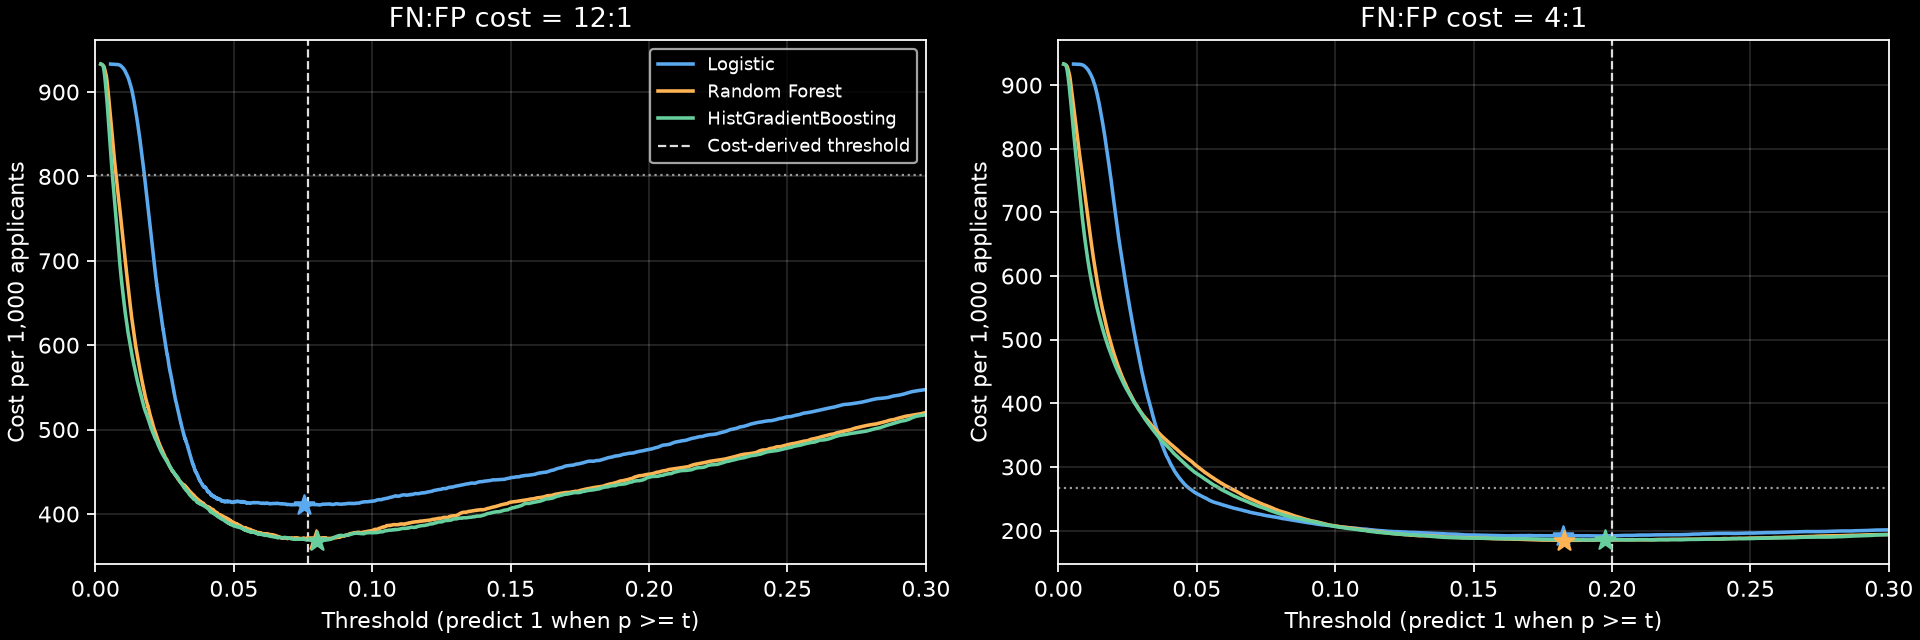

Decision estimator: FixedThresholdClassifier
Primary threshold (full precision): 0.07994084497831476
Threshold round-trip exact: True
Model fits in this section: 0
Final holdout evaluations: 0


In [5]:
section6_result, section6_choices = thresholding.save_study(
    section6_dir, source=section6_source, partition=section6_partition,
    integrity=section6_integrity, summary=section6_summary,
    operating_points=section6_operating_points, fold_results=section6_fold_results,
    audits=section6_audit, sensitivity=section6_sensitivity,
)
section6_classifier = thresholding.make_decision_estimator(section6_choices["primary"])
section6_pipeline = section6_classifier.estimator
section6_sensitivity_classifier = thresholding.make_decision_estimator(section6_choices["sensitivity_4_to_1"])

display(pd.DataFrame([
    section6_choices["primary"], section6_choices["sensitivity_4_to_1"]
])[["model", "fn_cost", "threshold", "development_cost_per_1000", "reduction_vs_baseline_percent"]].round(6))

section6_plot = section6_dir / "section_06_cost_curves.png"
thresholding.plot_cost_curves(section6_curves, section6_summary, section6_plot)
display(Image(filename=str(section6_plot)))
print("Decision estimator:", type(section6_classifier).__name__)
print("Primary threshold (full precision):", repr(section6_choices["primary"]["threshold"]))
print("Threshold round-trip exact:", section6_result["threshold_round_trip_exact"])
print("Model fits in this section:", section6_result["model_fits"])
print("Final holdout evaluations:", section6_result["holdout_evaluations"])

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۱۰. بخش هفت: ارزیابی کامل و پایداری

<p dir="rtl" style="direction:rtl;text-align:right;">مدل و آستانه اصلی بخش شش با نسبت هزینه ۱۲ به ۱ قفل می‌شوند. ابتدا خروجی پنج فولد توسعه بررسی می‌شود؛ سپس مدل فقط روی توسعه برازش و مجموعه نهایی یک بار امتیازدهی می‌شود. اجرای دوباره سلول، نتیجه ذخیره‌شده همان سیاست را می‌خواند و ارزیابی تازه‌ای انجام نمی‌دهد.</p>



</div>

In [2]:
import importlib
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from data_factory.database.connection import create_database_engine
import data_factory.credit_final_evaluation as evaluation

evaluation = importlib.reload(evaluation)
if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
section7_dir = PROJECT_ROOT / "stages/stage_03/evidence"
(section7_selection, section7_oof, section7_source,
 section7_partition, section7_development) = evaluation.development_evaluation(section7_dir)

print("Frozen model:", section7_selection["model"])
print("Frozen threshold (full precision):", repr(section7_selection["threshold"]))
print("Development records:", len(section7_oof))
print("Reserved final records:", len(section7_partition["holdout_row_ids"]))

Frozen model: hist_gradient_boosting
Frozen threshold (full precision): 0.07994084497831476
Development records: 120000
Reserved final records: 29999


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۰.۱. معیارها و پایداری توسعه

<p dir="rtl" style="direction:rtl;text-align:right;">Precision، Recall، F1، AUC و Accuracy بین صفر و یک‌اند؛ هزینه به ازای هزار متقاضی گزارش می‌شود. نتایج فولدهای توسعه توصیفی‌اند، چون انتخاب ویژگی/مدل/آستانه روی همین داده انجام شده است.</p>

<table dir="rtl" style="border-collapse:collapse;width:100%;line-height:1.8;"><thead><tr><th style="border:1px solid #777;padding:8px;text-align:right;">معیار</th><th style="border:1px solid #777;padding:8px;text-align:right;">معنا و محدودیت</th></tr></thead><tbody><tr><td dir="ltr" style="border:1px solid #777;padding:8px;vertical-align:top;"><code>precision</code></td><td dir="rtl" style="border:1px solid #777;padding:8px;text-align:right;white-space:normal;overflow-wrap:anywhere;">سهم نکول واقعی بین افراد پرخطر اعلام‌شده؛ نکول‌های ازدست‌رفته را نشان نمی‌دهد.</td></tr><tr><td dir="ltr" style="border:1px solid #777;padding:8px;vertical-align:top;"><code>recall</code></td><td dir="rtl" style="border:1px solid #777;padding:8px;text-align:right;white-space:normal;overflow-wrap:anywhere;">سهم نکول‌هایی که شناسایی شدند؛ رد اشتباهی افراد سالم را نشان نمی‌دهد.</td></tr><tr><td dir="ltr" style="border:1px solid #777;padding:8px;vertical-align:top;"><code>f1</code></td><td dir="rtl" style="border:1px solid #777;padding:8px;text-align:right;white-space:normal;overflow-wrap:anywhere;">توازن Precision و Recall؛ نسبت هزینه ۱۲ به ۱ را لحاظ نمی‌کند.</td></tr><tr><td dir="ltr" style="border:1px solid #777;padding:8px;vertical-align:top;"><code>roc_auc</code></td><td dir="rtl" style="border:1px solid #777;padding:8px;text-align:right;white-space:normal;overflow-wrap:anywhere;">توان رتبه‌بندی سالم و پرخطر در همه آستانه‌ها؛ هزینه تصمیم در آستانه منتخب را نشان نمی‌دهد.</td></tr><tr><td dir="ltr" style="border:1px solid #777;padding:8px;vertical-align:top;"><code>accuracy</code></td><td dir="rtl" style="border:1px solid #777;padding:8px;text-align:right;white-space:normal;overflow-wrap:anywhere;">سهم کل تصمیم‌های درست؛ فراوانی افراد سالم می‌تواند ضعف تشخیص نکول را پنهان کند.</td></tr><tr><td dir="ltr" style="border:1px solid #777;padding:8px;vertical-align:top;"><code>cost_per_1000</code></td><td dir="rtl" style="border:1px solid #777;padding:8px;text-align:right;white-space:normal;overflow-wrap:anywhere;">زیان موزون به ازای هزار متقاضی؛ به ماتریس هزینه و ترکیب متقاضی‌ها وابسته است.</td></tr></tbody></table>

</div>

In [3]:
section7_fold_table = pd.DataFrame(section7_development["folds"])
section7_stability_table = pd.DataFrame(section7_development["stability"])
display(section7_fold_table[[
    "fold", "precision", "recall", "f1", "roc_auc", "accuracy", "cost_per_1000",
]].round(4))
display(section7_stability_table.round(4))

,fold,precision,recall,f1,roc_auc,accuracy,cost_per_1000
0,1,0.2385,0.7523,0.3622,0.8712,0.8230,358.9733
1,2,0.2405,0.7153,0.3599,0.8530,0.8299,379.5517
2,3,0.2364,0.7213,0.3561,0.8596,0.8256,379.2658
3,4,0.2423,0.7369,0.3647,0.8674,0.8284,365.0152
4,5,0.2444,0.7427,0.3677,0.8671,0.8292,360.0683


,metric,mean,std,min,max
0,precision,0.2404,0.0031,0.2364,0.2444
1,recall,0.7337,0.0153,0.7153,0.7523
2,f1,0.3621,0.0045,0.3561,0.3677
3,roc_auc,0.8636,0.0073,0.8530,0.8712
4,accuracy,0.8272,0.0029,0.8230,0.8299
5,cost_per_1000,368.5749,10.1490,358.9733,379.5517


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۰.۲. ارزیابی یک‌باره نهایی

<p dir="rtl" style="direction:rtl;text-align:right;">Pipeline روی تمام ۱۲۰٬۰۰۰ رکورد توسعه fit می‌شود؛ هیچ آمار آماده‌سازی از مجموعه نهایی آموخته نمی‌شود. مدل برازش‌شده پیش از امتیازدهی ذخیره می‌شود. فقط سیاست اصلی ارزیابی می‌شود؛ مدل یا آستانه بعد از دیدن نتیجه تغییر نمی‌کند. فایل پیش‌بینی و نتیجه ذخیره‌شده، اجرای مجدد را بدون fit/predict تازه ممکن می‌کند.</p>



</div>

In [4]:
if "engine" not in globals():
    engine = create_database_engine()
(section7_result, section7_classifier,
 section7_predictions, section7_reused) = evaluation.evaluate_once(engine, section7_dir)
section7_pipeline = section7_classifier.estimator_

display(evaluation.metric_table(section7_result).round(6))
display(pd.DataFrame(section7_result["final"]["confusion_matrix"],
    index=["Actual healthy (0)", "Actual default (1)"],
    columns=["Predicted healthy (0)", "Predicted default (1)"]))
display(pd.DataFrame([{
    "baseline_accuracy": section7_result["baseline_final"]["accuracy"],
    "baseline_cost_per_1000": section7_result["baseline_final"]["cost_per_1000"],
    "model_cost_per_1000": section7_result["final"]["cost_per_1000"],
    "cost_reduction_percent": section7_result["reduction_vs_final_baseline_percent"],
    "meets_25_percent": section7_result["meets_25_percent_on_final"],
}]).round(6))
print("Existing final result reused:", section7_reused)
print("Final holdout evaluations:", section7_result["holdout_evaluations"])

,metric,development_oof,final_holdout
0,precision,0.240381,0.244035
1,recall,0.733699,0.739651
2,f1,0.362120,0.366988
3,roc_auc,0.863458,0.868346
4,accuracy,0.827225,0.829461
5,cost_per_1000,368.575000,361.945398


,Predicted healthy (0),Predicted default (1)
Actual healthy (0),23400,4594
Actual default (1),522,1483


,baseline_accuracy,baseline_cost_per_1000,model_cost_per_1000,cost_reduction_percent,meets_25_percent
0,0.933164,802.026734,361.945398,54.871155,True


Existing final result reused: False
Final holdout evaluations: 1


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۰.۳. فاصله توسعه و نهایی

<p dir="rtl" style="direction:rtl;text-align:right;">اختلاف هزینه به تغییر نرخ نکول، نرخ نکول ازدست‌رفته و نرخ هشدار اشتباه تجزیه می‌شود؛ این توصیف عددی، ادعای علت قطعی نیست. بازه ۹۵٪ هزینه با بوت‌استرپ گروه رکوردهای دارای ورودی یکسان محاسبه می‌شود؛ این بازه مشروط به همین مدل ثابت است و عدم‌قطعیت آموزش را شامل نمی‌شود.</p>



</div>

,cost_change_per_1000,relative_cost_change_percent,auc_change,prevalence_contribution,missed_default_contribution,false_alarm_contribution,development_cost_inside_final_bootstrap_interval
0,-6.629602,-1.798712,0.004888,-0.018497,-4.773529,-1.837576,True


,final_cost_ci_low,final_cost_ci_high,reduction_ci_low_percent,reduction_ci_high_percent,bootstrap_groups
0,344.8538,378.9042,52.7284,56.8696,29876


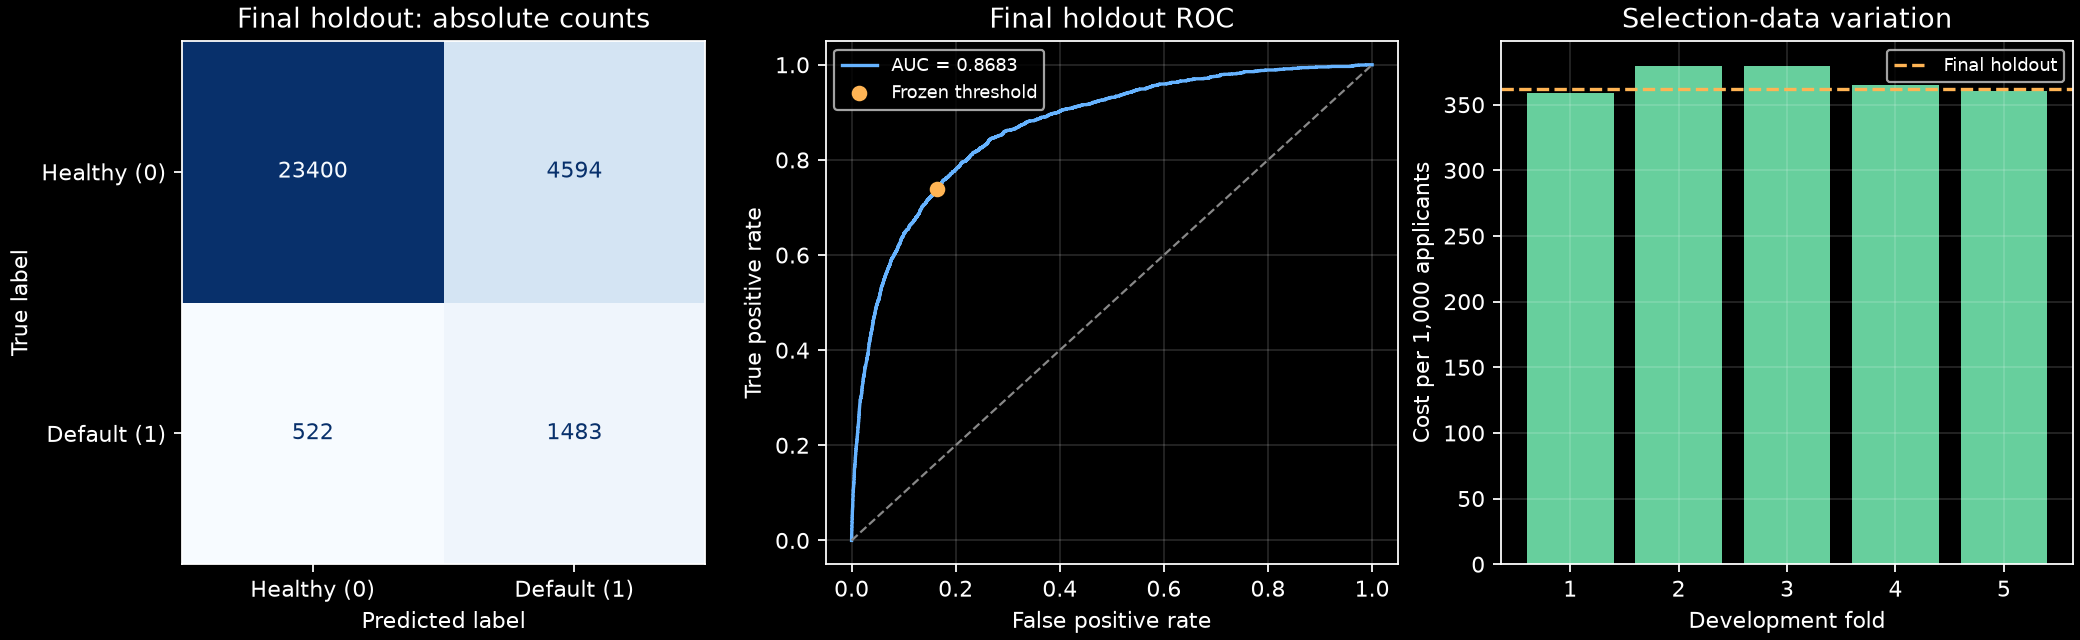

,row_id,target,probability,prediction
0,7,0,0.013264,0
1,10,0,0.036221,0
2,12,0,0.009524,0
3,14,1,0.646563,1
4,16,0,0.016417,0


Fitted decision model: stages\stage_03\evidence\section_07_fitted_classifier.joblib
Final evaluation: stages\stage_03\evidence\section_07_evaluation.json
Classifier is fitted: True


In [5]:
display(pd.DataFrame([section7_result["gap_analysis"]]).drop(columns="scope").round(6))
section7_uncertainty = section7_result["uncertainty"]
display(pd.DataFrame([{
    "final_cost_ci_low": section7_uncertainty["cost_per_1000_interval"][0],
    "final_cost_ci_high": section7_uncertainty["cost_per_1000_interval"][1],
    "reduction_ci_low_percent": section7_uncertainty["reduction_percent_interval"][0],
    "reduction_ci_high_percent": section7_uncertainty["reduction_percent_interval"][1],
    "bootstrap_groups": section7_uncertainty["groups"],
}]).round(4))

section7_plot = section7_dir / "section_07_evaluation.png"
evaluation.plot_evaluation(section7_result, section7_predictions, section7_plot)
display(Image(filename=str(section7_plot)))
display(section7_predictions[["row_id", "target", "probability", "prediction"]].head().round(6))
print("Fitted decision model:", (section7_dir / evaluation.MODEL_FILE).relative_to(PROJECT_ROOT))
print("Final evaluation:", (section7_dir / evaluation.RESULT_FILE).relative_to(PROJECT_ROOT))
print("Classifier is fitted:", hasattr(section7_classifier, "estimator_"))

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۱۱. بخش هشت: تفسیر و شناسنامه مدل

<p dir="rtl" style="text-align:right;">فقط سیاست منتخب HistGradientBoosting تفسیر می‌شود. اهمیت پنج ویژگی با افزایش هزینه پس از جابه‌جایی ورودی خام در پنج فولد توسعه سنجیده می‌شود؛ نشانگرها و ویژگی‌های مشتق‌شده داخل Pipeline دوباره محاسبه می‌شوند. پنج مدل کمکی با دستور ثابت برازش می‌شوند؛ مدل نهایی، آستانه و نتیجه بخش هفت تغییر نمی‌کنند.</p>

</div>

In [2]:
import importlib
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, HTML, clear_output
from data_factory.database.connection import create_database_engine
import data_factory.credit_interpretation as interpretation

# Keep dark defaults when Section 8 starts in a fresh kernel.
# Run once per kernel session: normal DataFrame displays now use dark colors.
# Keep pandas' normal row/column truncation and number formatting.
pd.set_option("display.notebook_repr_html", True)
_dataframe_dark_css = """
<style>
.dark-dataframe {
    background-color: #1e1e1e !important;
    color: #e0e0e0 !important;
    padding: 8px;
    overflow-x: auto;
}
.dark-dataframe table,
.dark-dataframe table td,
.dark-dataframe table th {
    background-color: #1e1e1e !important;
    color: #e0e0e0 !important;
    border-color: #444444 !important;
}
.dark-dataframe table th {
    background-color: #292929 !important;
}
.dark-dataframe table tbody tr:hover td,
.dark-dataframe table tbody tr:hover th {
    background-color: #333333 !important;
}
</style>
"""
_ = get_ipython().display_formatter.formatters["text/html"].for_type(
    pd.DataFrame,
    lambda frame: (
        _dataframe_dark_css
        + '<div class="dark-dataframe">'
        + frame._repr_html_()
        + '</div>'
    ),
)

interpretation = importlib.reload(interpretation)
if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
section8_dir = PROJECT_ROOT / "stages/stage_03/evidence"
if "engine" not in globals():
    engine = create_database_engine()
section8_result = interpretation.analyze(engine, section8_dir, repeats=5, progress=print)
clear_output(wait=True)
print("Model:", section8_result["selection"]["model"])
print("Frozen threshold:", repr(section8_result["selection"]["threshold"]))
print("Scope: development only; records:", section8_result["development_records"])
print("Final refits / new holdout evaluations:", section8_result["final_model_fits"], section8_result["holdout_evaluations"])

Model: hist_gradient_boosting
Frozen threshold: 0.07994084497831476
Scope: development only; records: 120000
Final refits / new holdout evaluations: 0 0


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۱.۱. پنج ویژگی مؤثر و شهود کسب‌وکار

<p dir="rtl" style="text-align:right;">افزایش بیشترِ هزینه یعنی وابستگی بیشتر مدل به آن ورودی؛ مقدار منفی یعنی جابه‌جایی در این آزمایش هزینه را کم کرده است. انحراف معیار بین فولدها گزارش می‌شود. اهمیت جهت یا علت را نشان نمی‌دهد؛ نرخ نکول بازه‌ها برای مقایسه با شهود آمده است. هم‌بستگی ورودی‌ها و ترکیب‌های غیرواقعی حاصل از جابه‌جایی، محدودیت روش‌اند.</p>

</div>

In [3]:
section8_top_five = pd.DataFrame(section8_result["top_five"])
display(section8_top_five[["rank", "feature", "cost_increase_per_1000", "fold_std", "mean_fold_auc_decrease"]].round(5))
section8_review = pd.DataFrame(section8_result["business_review"])
section8_review["observed_comparison"] = section8_review["observed_comparison"].str.replace(
    r"\[[^)\]]+\)|under_35|65_plus|\d+\+", lambda match: "\u2066" + match.group(0) + "\u2069", regex=True,
)
with pd.option_context("display.max_colwidth", None):
    display(HTML(_dataframe_dark_css + '<div class="dark-dataframe" dir="rtl"><style>.section8-review td,.section8-review th{white-space:normal!important;overflow-wrap:anywhere;text-align:right;vertical-align:top;padding:9px}.section8-review{width:100%;table-layout:fixed}.section8-review td:first-child{direction:ltr;text-align:left}</style>' + section8_review[["feature", "observed_comparison", "business_alignment"]].to_html(index=False, classes="section8-review", escape=True) + '</div>'))
display(pd.DataFrame(section8_result["observed_risk_profiles"]).query("feature in @section8_top_five.feature").round(5))
section8_debt_check = section8_result["debt_ratio_investigation"]
display(pd.DataFrame([{k: v for k, v in section8_debt_check.items() if k != "interpretation"}]).T)
print(section8_debt_check["interpretation"])

,rank,feature,cost_increase_per_1000,fold_std,mean_fold_auc_decrease
0,1,RevolvingUtilizationOfUnsecuredLines,90.90500,4.85945,0.07246
1,2,NumberOfTime30-59DaysPastDueNotWorse,57.99833,5.80613,0.03269
2,3,NumberOfTimes90DaysLate,57.81333,6.85317,0.03415
3,4,NumberOfTime60-89DaysPastDueNotWorse,33.05167,3.18703,0.01758
4,5,age,22.16167,4.33309,0.01021


feature,observed_comparison,business_alignment
RevolvingUtilizationOfUnsecuredLines,"نرخ نکول مشاهده‌شده در بازه ⁦[-inf, 0.25)⁩ برابر 2.2٪ و در بازه ⁦[1.0, inf)⁩ برابر 36.9٪ است.",مقایسه بازه کم و زیاد با شهود ریسک سازگار است؛ رابطه علّی نتیجه نمی‌شود.
NumberOfTime30-59DaysPastDueNotWorse,نرخ نکول مشاهده‌شده در بازه 0 برابر 4.0٪ و در بازه ⁦2+⁩ برابر 31.4٪ است.,مقایسه بازه کم و زیاد با شهود ریسک سازگار است؛ رابطه علّی نتیجه نمی‌شود.
NumberOfTimes90DaysLate,نرخ نکول مشاهده‌شده در بازه 0 برابر 4.6٪ و در بازه ⁦2+⁩ برابر 54.9٪ است.,مقایسه بازه کم و زیاد با شهود ریسک سازگار است؛ رابطه علّی نتیجه نمی‌شود.
NumberOfTime60-89DaysPastDueNotWorse,نرخ نکول مشاهده‌شده در بازه 0 برابر 5.1٪ و در بازه ⁦2+⁩ برابر 52.4٪ است.,مقایسه بازه کم و زیاد با شهود ریسک سازگار است؛ رابطه علّی نتیجه نمی‌شود.
age,نرخ نکول مشاهده‌شده در بازه ⁦65_plus⁩ برابر 2.5٪ و در بازه ⁦under_35⁩ برابر 11.2٪ است.,مقایسه بازه کم و زیاد با شهود ریسک سازگار است؛ رابطه علّی نتیجه نمی‌شود.


,feature,bin,records,positives,default_rate
0,RevolvingUtilizationOfUnsecuredLines,"[0.5, 1.0)",30322,4629,0.15266
1,RevolvingUtilizationOfUnsecuredLines,"[-inf, 0.25)",70151,1522,0.02170
2,RevolvingUtilizationOfUnsecuredLines,"[0.25, 0.5)",16867,888,0.05265
3,RevolvingUtilizationOfUnsecuredLines,"[1.0, inf)",2660,982,0.36917
4,age,35_to_49,37792,3295,0.08719
5,age,under_35,15406,1721,0.11171
6,age,65_plus,24901,621,0.02494
7,age,50_to_64,41901,2384,0.05690
8,NumberOfTime30-59DaysPastDueNotWorse,2+,6169,1940,0.31448
9,NumberOfTime30-59DaysPastDueNotWorse,0,100813,4053,0.04020


,0
high_ratio_definition,DebtRatio >= 10
comparison_definition,0.5 <= DebtRatio < 1
high_ratio_records,23242
comparison_records,16779
high_ratio_default_rate,0.054772
comparison_default_rate,0.098516
missing_or_zero_income_share_in_high_ratio,0.977024


مقادیر بسیار بزرگ نسبت لزوماً ریسک بالاتر ندارند؛ همراهی با درآمد صفر/گمشده و ابهام معنای نسبت بررسی شد. این ارتباط علت قطعی یا مجوز تغییر داده نیست.


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۱.۲. انصاف سنی و سه موقعیت شکست

<p dir="rtl" style="text-align:right;">پیش‌بینی‌های OOF قبلی با همان آستانه بین چهار گروه سنی مقایسه می‌شوند. FPR بالاتر یعنی هشدار اشتباه بیشتر بین افراد سالم؛ Recall کمتر یعنی نکول ازدست‌رفته بیشتر. نرخ پایه و تعداد نمونه را هم باید دید. بازه‌های ویلسون تقریبی‌اند و اثر انتخاب مدل یا گروه رکوردهای یکسان را لحاظ نمی‌کنند. این ممیزی توصیفیِ توسعه، اثبات تبعیض یا تأیید انصاف نیست. سه گروه شکست می‌توانند هم‌پوشانی داشته باشند و الزاماً از کل داده بدتر نیستند.</p>

</div>

In [4]:
section8_age = pd.DataFrame(section8_result["age_fairness"])
display(section8_age[["age_group", "records", "positives", "positive_rate", "precision", "recall", "false_negative_rate", "false_positive_rate", "cost_per_1000"]].round(5))
display(section8_age[["age_group", "recall_ci95", "fpr_ci95"]])
section8_failures = pd.DataFrame(section8_result["failure_scenarios"])
display(section8_failures[["scenario", "records", "false_negative", "false_positive", "recall", "precision", "cost_per_1000"]].round(5))
with pd.option_context("display.max_colwidth", None):
    display(HTML(_dataframe_dark_css + '<div class="dark-dataframe" dir="rtl"><style>.section8-failures{width:100%;table-layout:fixed}.section8-failures td,.section8-failures th{white-space:normal!important;overflow-wrap:anywhere;text-align:right;vertical-align:top;padding:9px}</style>' + section8_failures[["label", "mechanism"]].to_html(index=False, classes="section8-failures", escape=True) + '</div>'))

,age_group,records,positives,positive_rate,precision,recall,false_negative_rate,false_positive_rate,cost_per_1000
0,under_35,15406,1721,0.11171,0.24287,0.82103,0.17897,0.32189,525.83409
1,35_to_49,37792,3295,0.08719,0.24497,0.77178,0.22822,0.22721,446.17909
2,50_to_64,41901,2384,0.05690,0.23565,0.67827,0.32173,0.13273,344.83664
3,65_plus,24901,621,0.02494,0.21956,0.50242,0.49758,0.04568,193.44605


,age_group,recall_ci95,fpr_ci95
0,under_35,"[0.8022151500374108, 0.8384234398742143]","[0.314108612707413, 0.32976190660094745]"
1,35_to_49,"[0.7571337591632306, 0.7857841174176787]","[0.2228168627158334, 0.23166021076470023]"
2,50_to_64,"[0.6592461778248553, 0.6967238539626812]","[0.129418215669343, 0.13610855631892302]"
3,65_plus,"[0.4631968112157237, 0.5416044066894744]","[0.043120435089897116, 0.048374210128750844]"


,scenario,records,false_negative,false_positive,recall,precision,cost_per_1000
0,clean_history,95655,1754,6265,0.33181,0.12206,285.53656
1,high_utilization,2660,20,1367,0.97963,0.41305,604.13534
2,incomplete_record,23931,311,2858,0.77382,0.27129,275.37504


label,mechanism
سابقه بدون دیرکرد ثبت‌شده,متقاضی بدون دیرکرد قبلی ممکن است پس از شوک درآمد یا اشتغال نکول کند؛ مدل این شوک آینده را مشاهده نمی‌کند.
استفاده حداقل ۱۰۰٪ از اعتبار,استفاده بالا همیشه به نکول منجر نمی‌شود؛ افراد سالم نیز ممکن است اشتباه پرخطر اعلام شوند.
پرونده دارای مقدار گمشده یا کد ویژه,میانه‌گذاری و نشانگر، درآمد واقعی یا معنای کد ویژه را بازیابی نمی‌کنند؛ پرونده ناقص همچنان خطا دارد.


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۱.۳. شناسنامه و شواهد

<p dir="rtl" style="text-align:right;">شناسنامه کوتاه، کاربرد، داده آموزشی، ارزیابی ثبت‌شده، محدودیت‌ها و جمعیت‌های نامناسب را جمع‌بندی می‌کند. معیار نهایی از فایل بخش هفت خوانده می‌شود؛ امتیازدهی نهایی تازه‌ای انجام نمی‌شود. تحلیل توسعه برای توضیح سیاست ثابت است و انتخاب مجدد مدل/ویژگی/آستانه انجام نمی‌دهد.</p>

</div>

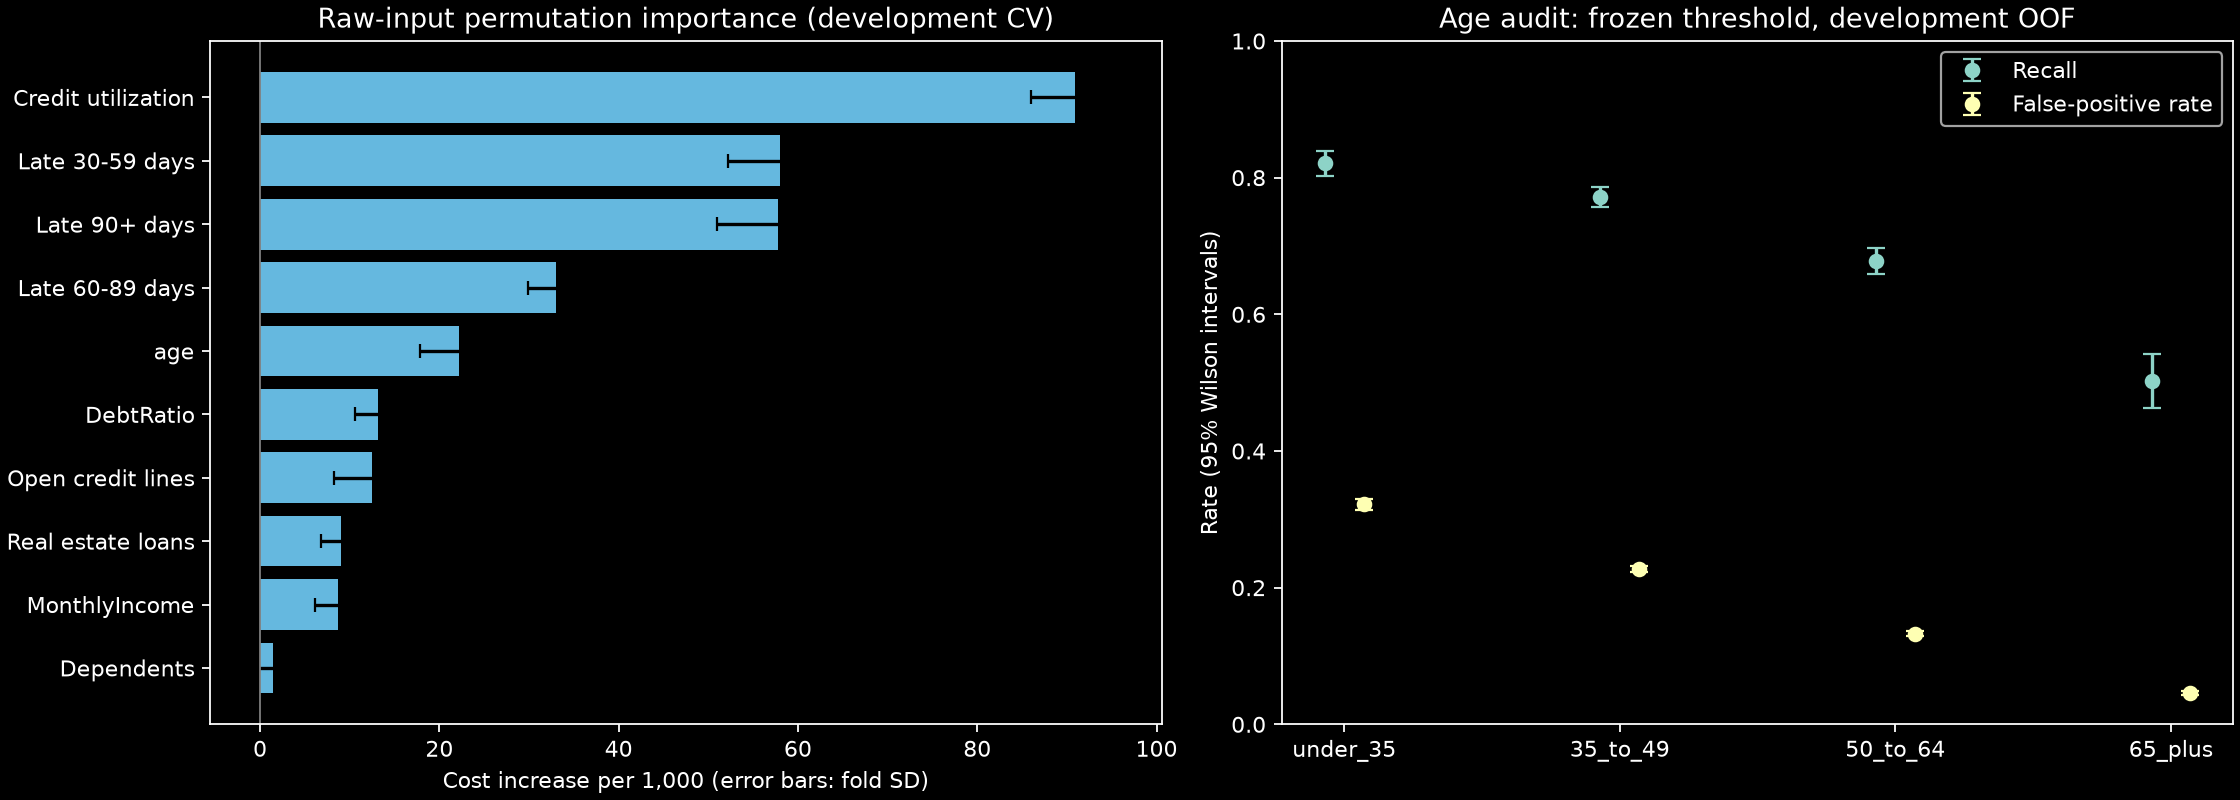

,fold,train_records,validation_records,oof_probability_max_error,row_overlap,group_overlap,parameters_unchanged
0,1,96001,23999,0.0,0,0,True
1,2,95998,24002,0.0,0,0,True
2,3,96001,23999,0.0,0,0,True
3,4,96001,23999,0.0,0,0,True
4,5,95999,24001,0.0,0,0,True


Interpretation evidence: stages\stage_03\evidence\section_08_interpretation.json
Model card: stages\stage_03\model_card.md


In [ ]:
section8_plot = section8_dir / "section_08_interpretation.png"
interpretation.plot_interpretation(section8_result, section8_plot)
display(Image(filename=str(section8_plot)))
section8_card_path = PROJECT_ROOT / "stages/stage_03/model_card.md"
section8_card = interpretation.write_model_card(section8_result, section8_dir, section8_card_path)
display(pd.DataFrame(section8_result["fit_audit"])[[
    "fold", "train_records", "validation_records", "oof_probability_max_error",
    "row_overlap", "group_overlap", "parameters_unchanged",
]])
print("Interpretation evidence:", (section8_dir / interpretation.RESULT_FILE).relative_to(PROJECT_ROOT))
print("Model card:", section8_card_path.relative_to(PROJECT_ROOT))

<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

## ۱۲. بخش نه: مهندسی و مسیر پیش‌بینی

<p dir="rtl">منطق مدل زیر src است؛ فایل joblib بخش هفت، آماده‌سازی، طبقه‌بند و آستانه ثابت را نگه می‌دارد. تابع و CLI جدید، فایل تازه با همان ده ویژگی خام را می‌گیرند؛ row_id و هدف اختیاری‌اند و در پیش‌بینی نقش ندارند. این مسیر به دیتابیس وصل نمی‌شود و fit نمی‌کند.</p>

</div>

In [1]:
import json
import subprocess
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from data_factory.credit_inference import load_classifier, predict_frame
from data_factory.credit_missingness import write_json

import pandas as pd
from IPython.display import display

# Run once per kernel session: normal DataFrame displays now use dark colors.
# Keep pandas' normal row/column truncation and number formatting.
pd.set_option("display.notebook_repr_html", True)
_dataframe_dark_css = """
<style>
.dark-dataframe {
    background-color: #1e1e1e !important;
    color: #e0e0e0 !important;
    padding: 8px;
    overflow-x: auto;
}
.dark-dataframe table,
.dark-dataframe table td,
.dark-dataframe table th {
    background-color: #1e1e1e !important;
    color: #e0e0e0 !important;
    border-color: #444444 !important;
}
.dark-dataframe table th {
    background-color: #292929 !important;
}
.dark-dataframe table tbody tr:hover td,
.dark-dataframe table tbody tr:hover th {
    background-color: #333333 !important;
}
</style>
"""
_ = get_ipython().display_formatter.formatters["text/html"].for_type(
    pd.DataFrame,
    lambda frame: (
        _dataframe_dark_css
        + '<div class="dark-dataframe">'
        + frame._repr_html_()
        + '</div>'
    ),
)

if "PROJECT_ROOT" not in globals():
    roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    roots += [root / "machine_learning_challenge" for root in roots[:]]
    PROJECT_ROOT = next(root for root in roots if (root / "config/credit_schema.json").is_file())
section9_dir = PROJECT_ROOT / "stages/stage_03/evidence"
section9_model_path = section9_dir / "section_07_fitted_classifier.joblib"
section9_sample_path = PROJECT_ROOT / "stages/stage_03/examples/new_applicants.csv"
section9_classifier, section9_metadata = load_classifier(section9_model_path)
section9_sample = pd.read_csv(section9_sample_path)
section9_api_predictions = predict_frame(section9_sample, section9_classifier)
print("Loaded frozen model:", section9_metadata["selection"]["model"])
print("Threshold:", repr(section9_classifier.threshold))
print("Sample: six synthetic applicants; no performance evaluation.")
display(section9_api_predictions)

Loaded frozen model: hist_gradient_boosting
Threshold: 0.07994084497831476
Sample: six synthetic applicants; no performance evaluation.


,row_id,probability_default,prediction
0,900000001,0.008142,0
1,900000002,0.513440,1
2,900000003,0.020221,0
3,900000004,0.528975,1
4,900000005,0.475852,1
5,900000006,0.004167,0


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۲.۱. اجرای فایل تازه

<p dir="rtl">دستور predict-credit فایل را دسته‌ای پردازش و فقط پس از موفقیت کامل خروجی را منتشر می‌کند. ستون record_number ترتیب ورودی را مشخص می‌کند؛ row_id در صورت وجود حفظ می‌شود. probability_default احتمال کلاس ۱ و prediction تصمیم با همان آستانه ثابت است. ستون اضافی، ساختار خراب یا مقدار نامعتبر رد می‌شود؛ هدف هرگز برای تصمیم استفاده نمی‌شود.</p>

</div>

In [2]:
section9_output_path = section9_dir / "section_09_example_predictions.csv"
section9_command = [
    sys.executable, "-m", "data_factory", "predict-credit",
    "--input", str(section9_sample_path), "--output", str(section9_output_path),
    "--model", str(section9_model_path), "--batch-size", "2",
]
section9_process = subprocess.run(section9_command, cwd=PROJECT_ROOT,
    capture_output=True, text=True, encoding="utf-8")
if section9_process.returncode:
    raise RuntimeError(section9_process.stderr or section9_process.stdout)
section9_execution = json.loads(section9_process.stdout)
section9_predictions = pd.read_csv(section9_output_path, float_precision="round_trip")
section9_same = (
    np.array_equal(section9_api_predictions.probability_default.to_numpy(), section9_predictions.probability_default.to_numpy())
    and np.array_equal(section9_api_predictions.prediction.to_numpy(), section9_predictions.prediction.to_numpy())
)
if not section9_same:
    raise RuntimeError("Python API and CSV CLI predictions differ.")
display(section9_predictions)
display(pd.DataFrame([{k: section9_execution[k] for k in [
    "records", "predicted_default", "batches", "model_fits", "database_reads",
    "holdout_evaluations", "preprocessing_unchanged",
]}]))

,record_number,row_id,probability_default,prediction
0,1,900000001,0.008142,0
1,2,900000002,0.513440,1
2,3,900000003,0.020221,0
3,4,900000004,0.528975,1
4,5,900000005,0.475852,1
5,6,900000006,0.004167,0


,records,predicted_default,batches,model_fits,database_reads,holdout_evaluations,preprocessing_unchanged
0,6,3,3,0,0,0,True


<div dir="rtl" style="direction:rtl;text-align:right;line-height:1.9;">

### ۱۲.۲. وضعیت تحویل

<p dir="rtl">نمونه شش‌ردیفی ساختگی است و شاهد عملکرد واقعی مدل نیست. مدل، داده و شواهد قبلی تغییر نمی‌کنند. تعداد commitهای مرتبط از تاریخچه واقعی خوانده می‌شود؛ commit مصنوعی ساخته نمی‌شود. صورت سؤال حداقل هشت تست می‌خواهد؛ طبق درخواست کاربر تست جدید نوشته یا اجرا نشده و این الزام باز مانده است.</p>

</div>

In [3]:
try:
    section9_history = subprocess.run([
        "git", "log", "--format=%h %s", "--", "stages/stage_03", "src/data_factory/credit_*.py",
    ], cwd=PROJECT_ROOT, capture_output=True, text=True, encoding="utf-8", check=True).stdout.splitlines()
    section9_head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT,
        capture_output=True, text=True, encoding="utf-8", check=True).stdout.strip()
    section9_git = {"available": True, "head": section9_head,
        "related_commit_count": len(section9_history), "minimum_required": 10,
        "minimum_met": len(section9_history) >= 10, "recent_related_commits": section9_history[:10]}
except (OSError, subprocess.CalledProcessError):
    section9_git = {"available": False, "minimum_required": 10,
        "note": "Git history is unavailable in this copy; inference remains independent of Git."}
section9_evidence = {
    "section": "Challenge 3 Section 9: engineering and fresh-file inference",
    "execution": {k: v for k, v in section9_execution.items() if k not in ["input_file", "output_file", "model_file"]},
    "files": {"input": str(section9_sample_path.relative_to(PROJECT_ROOT)),
        "output": str(section9_output_path.relative_to(PROJECT_ROOT)),
        "model": str(section9_model_path.relative_to(PROJECT_ROOT))},
    "python_api_matches_cli": section9_same, "sample_is_synthetic": True,
    "git": section9_git,
    "software_tests": {"required_by_assignment": 8, "added": 0, "executed": False,
        "status": "omitted_at_user_request; assignment requirement remains unmet"},
    "scope": "Inference demonstration only; no DB reads, training, threshold selection or new holdout evaluation. Existing final metrics remain unchanged.",
}
write_json(section9_dir / "section_09_inference.json", section9_evidence)
print("Python API matches CSV CLI:", section9_same)
print("Existing related commits:", section9_git.get("related_commit_count", "unavailable"))
print("Software tests: not added or run, as requested.")
print("Evidence:", (section9_dir / "section_09_inference.json").relative_to(PROJECT_ROOT))

Python API matches CSV CLI: True
Existing related commits: 21
Software tests: not added or run, as requested.
Evidence: stages\stage_03\evidence\section_09_inference.json
